# 🏭 Pakistan Sugar Mills: Big Data Analytics, Data Warehousing & Data Mining

**Courses:** Big Data Analytics · Data Warehouse and Data Mining
**Tools:** PySpark (Spark SQL, Spark MLlib), pandas, matplotlib, seaborn, scikit-learn (metrics only)

<a href="https://colab.research.google.com/github/GITHUB_USERNAME/pakistan-sugar-mills-analytics/blob/main/notebooks/Pakistan_Sugar_Mills_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Problem statement
Pakistan is one of the world's larger sugar producers, with roughly 80+ mills in Punjab, Sindh and Khyber Pakhtunkhwa (KPK).
Every crushing season (November to April) mills buy millions of tonnes of sugarcane from growers, crush it and turn about 9 to 10% of it into sugar
(the **recovery rate**). Three recurring problems in the industry are:
1. **Low and variable sugar recovery**, which wastes cane and raises cost per kg of sugar.
2. **Late payments to cane growers**, a long-standing complaint in Punjab and Sindh.
3. **Unequal mill performance** (old vs modern mills, cogeneration, breakdowns).

## Objectives
| # | Objective | Course topic |
|---|---|---|
| 1 | Ingest and clean ~2.5 million procurement records + ~86k mill-day records with PySpark | Big Data |
| 2 | Design and build a **galaxy (fact constellation) schema** data warehouse, stored as partitioned Parquet | Data Warehouse |
| 3 | Run **OLAP operations** (roll-up, drill-down, slice, dice, pivot, cube) with Spark SQL | Data Warehouse |
| 4 | Predict **daily sugar recovery %** (regression: Linear, Random Forest, GBT) | Machine Learning |
| 5 | Predict **late grower payments** (classification: Logistic Regression, Random Forest, GBT) | Machine Learning |
| 6 | **K-Means clustering** of mills into performance segments | Data Mining |
| 7 | **FP-Growth association rules** on cane receipts | Data Mining |

## Dataset (hybrid: real + simulated)
* **Real data (`data/real/`)**: published PBS, PSMA, Crop Reporting Service Punjab, Economic Survey and USDA GAIN figures:
  province-wise cane area/production 2000-2023, mill crushing and recovery 1997-2011, national crushing 2015-2020 and minimum support prices.
* **Simulated big data (`data/synthetic/`)**: mill-level and receipt-level data is not published in Pakistan, so it was generated by
  `src/generate_data.py` and **calibrated to the real figures** (national cane crushed and sugar produced per season, province shares,
  recovery levels, support prices, crushing calendar). Mill names are anonymised codes; district names and cane variety codes are real.
  All mill, grower and receipt values are simulated and must not be read as facts about any real mill.

| Table | Rows | Grain |
|---|---|---|
| `cane_procurement/*.csv.gz` | ~2.46 million | one weighbridge receipt (cane delivery) |
| `daily_crushing.csv.gz` | ~86,000 | one mill on one crushing day |
| `mills.csv` | 85 | mill |
| `growers.csv.gz` | ~86,000 | cane grower |
| `varieties.csv`, `districts.csv` | small | lookup |

## 0. Setup
In **Google Colab**: set `GITHUB_USERNAME` below to your GitHub username, then run all cells (Runtime → Run all).
The cell installs PySpark, clones the repository and (if needed) regenerates the dataset. Running locally needs Python 3.9+, Java 11/17 and `pip install -r requirements.txt`.

In [15]:
# ONE-TIME FIX: download the repo and rebuild the correct folder structure in Colab
import os, glob, shutil, subprocess
RAW = "/content/repo_raw"                                   # flat copy downloaded from GitHub
P = "/content/pakistan-sugar-mills-analytics"               # correctly organised project folder
shutil.rmtree(RAW, ignore_errors=True); shutil.rmtree(P, ignore_errors=True)
subprocess.run(["git", "clone", "-q", "--depth", "1",
                "https://github.com/f2023-293/pakistan-sugar-mills-analytics.git", RAW], check=True)

# where each file must go (folder -> file names)
layout = {
    "data/real": ["SOURCES.md", "sugar_industry_province_1997_2011.csv", "sugar_national_crushing_2015_2020.csv",
                  "sugarcane_area_production_province_2000_2023.csv", "sugarcane_min_support_price_2013_2024.csv",
                  "sugarcane_national_2015_2026.csv"],
    "data/synthetic": ["daily_crushing.csv.gz", "districts.csv", "growers.csv.gz", "mills.csv", "varieties.csv"],
    "data/synthetic/cane_procurement": [f"procurement_{y}_{str(y+1)[2:]}.csv.gz" for y in range(2015, 2025)],
    "src": ["generate_data.py", "draw_star_schema.py"],
    "docs": ["star_schema.png"],
}
for folder, names in layout.items():
    os.makedirs(os.path.join(P, folder), exist_ok=True)
    for name in names:
        found = glob.glob(os.path.join(RAW, "**", name), recursive=True)
        if found:
            shutil.copy(found[0], os.path.join(P, folder, name))
        else:
            print("MISSING:", name)
print("Files in data/real:", sorted(os.listdir(f"{P}/data/real")))
print("Procurement files:", len(os.listdir(f"{P}/data/synthetic/cane_procurement")))

Files in data/real: ['SOURCES.md', 'sugar_industry_province_1997_2011.csv', 'sugar_national_crushing_2015_2020.csv', 'sugarcane_area_production_province_2000_2023.csv', 'sugarcane_min_support_price_2013_2024.csv', 'sugarcane_national_2015_2026.csv']
Procurement files: 10


In [16]:
import os, sys, subprocess, shutil, time, warnings
warnings.filterwarnings("ignore")

GITHUB_USERNAME = "f2023-293"          # <-- change this to your GitHub username
REPO_NAME = "pakistan-sugar-mills-analytics"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if shutil.which("java") is None:                 # Spark needs Java
        subprocess.run("apt-get -qq install -y openjdk-17-jre-headless > /dev/null", shell=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3"])
    PROJECT_DIR = f"/content/{REPO_NAME}"
    if not os.path.exists(PROJECT_DIR):
        subprocess.run(["git", "clone", "--depth", "1",
                        f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git", PROJECT_DIR])
else:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()

DATA = os.path.join(PROJECT_DIR, "data")
if not os.path.exists(os.path.join(DATA, "synthetic", "daily_crushing.csv.gz")):
    print("Dataset not found, generating it (about 1 minute)...")
    subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "src", "generate_data.py")], check=True)

WAREHOUSE = os.path.join(PROJECT_DIR, "warehouse")
FIG_DIR = os.path.join(PROJECT_DIR, "outputs", "figures")
OUT_DIR = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(FIG_DIR, exist_ok=True)
print("Project folder:", PROJECT_DIR)
print("Running in Colab:", IN_COLAB)

Project folder: /content/pakistan-sugar-mills-analytics
Running in Colab: True


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType, DoubleType, DateType)

spark = (SparkSession.builder
         .appName("PakistanSugarMills")
         .master("local[*]")
         .config("spark.driver.memory", "6g" if IN_COLAB else "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()

print("Spark version:", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Spark version: 3.5.3 | cores: 2


## 1. Real data: the industry at a glance
Small official tables, so pandas is enough here. They give context and the calibration targets for the simulated data.

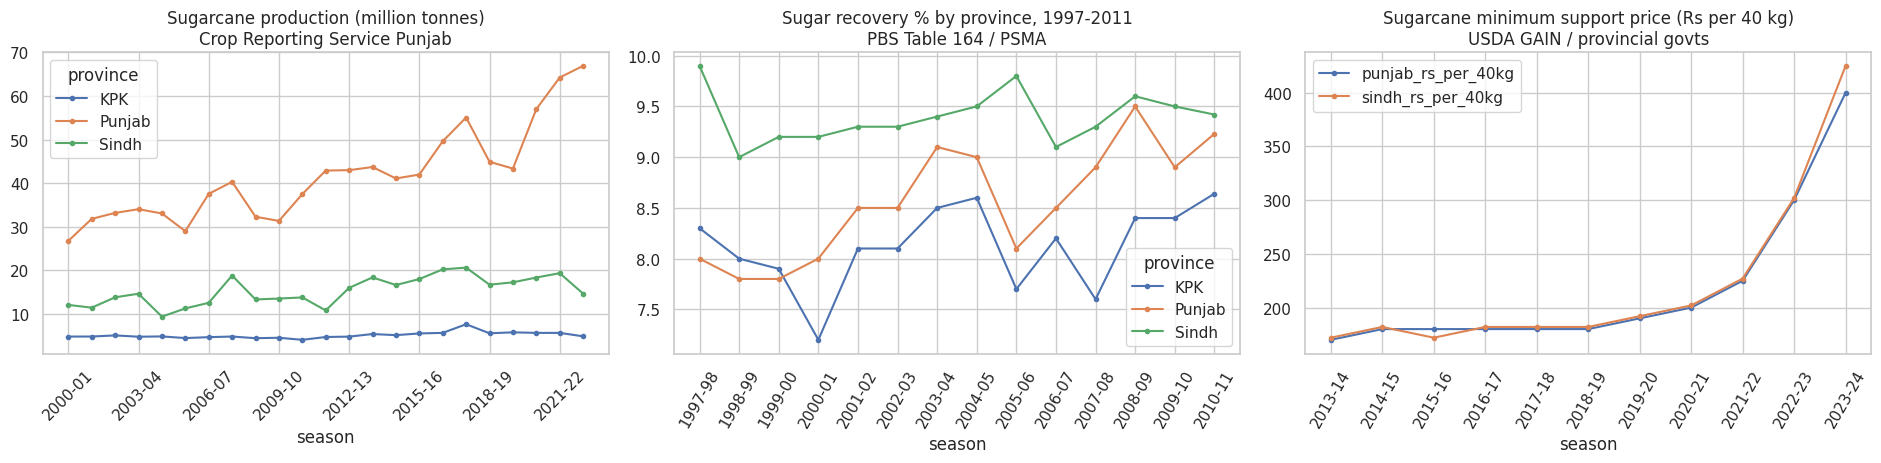

,avg_recovery,avg_mills,avg_crushed_mt
province,,,
KPK,8.12,5.79,1.87
Punjab,8.56,40.07,24.25
Sindh,9.39,28.36,11.90


In [18]:
real_area = pd.read_csv(f"{DATA}/real/sugarcane_area_production_province_2000_2023.csv")
real_mills = pd.read_csv(f"{DATA}/real/sugar_industry_province_1997_2011.csv")
real_nat = pd.read_csv(f"{DATA}/real/sugar_national_crushing_2015_2020.csv")
msp = pd.read_csv(f"{DATA}/real/sugarcane_min_support_price_2013_2024.csv")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
pv = (real_area[real_area.province != "Balochistan"]
      .pivot(index="season", columns="province", values="production_000_tonnes") / 1000)
pv.plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Sugarcane production (million tonnes)\nCrop Reporting Service Punjab")
ax[0].set_xticks(range(0, len(pv), 3)); ax[0].set_xticklabels(pv.index[::3], rotation=45)

rv = real_mills.pivot(index="season", columns="province", values="recovery_pct")
rv.plot(ax=ax[1], marker="o", ms=3)
ax[1].set_title("Sugar recovery % by province, 1997-2011\nPBS Table 164 / PSMA")
ax[1].set_xticks(range(len(rv))); ax[1].set_xticklabels(rv.index, rotation=60)

msp.set_index("season")[["punjab_rs_per_40kg", "sindh_rs_per_40kg"]].plot(ax=ax[2], marker="o", ms=3)
ax[2].set_title("Sugarcane minimum support price (Rs per 40 kg)\nUSDA GAIN / provincial govts")
ax[2].set_xticks(range(len(msp))); ax[2].set_xticklabels(msp.season, rotation=60)
savefig("01_real_data_overview.png")

summary = real_mills.groupby("province").agg(avg_recovery=("recovery_pct", "mean"),
                                             avg_mills=("no_of_mills", "mean"),
                                             avg_crushed_mt=("cane_crushed_mt", "mean")).round(2)
summary

**Observations (real data):** Punjab grows roughly two-thirds of Pakistan's cane, but Sindh mills consistently report a higher recovery rate
(warmer winters, longer-matured cane). Support prices were flat for years and then more than doubled between 2020-21 and 2023-24,
which raises the cost of every tonne of cane crushed.

## 2. Big data ingestion with PySpark
We read all 10 seasonal procurement files at once using a wildcard path and an **explicit schema**
(faster and safer than `inferSchema` on millions of rows).

In [19]:
procurement_schema = StructType([
    StructField("receipt_id", StringType()),      StructField("season", StringType()),
    StructField("receipt_date", DateType()),      StructField("receipt_hour", IntegerType()),
    StructField("mill_id", StringType()),         StructField("grower_id", StringType()),
    StructField("variety_code", StringType()),    StructField("transport_mode", StringType()),
    StructField("distance_km", DoubleType()),     StructField("harvest_to_crush_hrs", DoubleType()),
    StructField("gross_weight_t", DoubleType()),  StructField("trash_pct", DoubleType()),
    StructField("deduction_t", DoubleType()),     StructField("net_weight_t", DoubleType()),
    StructField("cane_pol_pct", DoubleType()),    StructField("price_rs_per_40kg", DoubleType()),
    StructField("amount_rs", DoubleType()),       StructField("payment_delay_days", IntegerType()),
    StructField("payment_mode", StringType()),
])

t0 = time.time()
raw_proc = spark.read.csv(f"{DATA}/synthetic/cane_procurement/*.csv.gz", header=True, schema=procurement_schema)
raw_daily = (spark.read.csv(f"{DATA}/synthetic/daily_crushing.csv.gz", header=True, inferSchema=True)
             .withColumn("date", F.to_date("date")))
mills_src = spark.read.csv(f"{DATA}/synthetic/mills.csv", header=True, inferSchema=True)
growers_src = spark.read.csv(f"{DATA}/synthetic/growers.csv.gz", header=True, inferSchema=True)
varieties_src = spark.read.csv(f"{DATA}/synthetic/varieties.csv", header=True, inferSchema=True)

counts = {name: df.count() for name, df in [("cane_procurement", raw_proc), ("daily_crushing", raw_daily),
                                            ("mills", mills_src), ("growers", growers_src), ("varieties", varieties_src)]}
print(f"Loaded in {time.time()-t0:.1f} s")
for k, v in counts.items():
    print(f"  {k:<18}{v:>12,} rows")
print("Procurement input partitions:", raw_proc.rdd.getNumPartitions(), "(gzip files are not splittable: 1 partition per file)")
raw_proc.printSchema()
raw_proc.show(5, truncate=False)

Loaded in 34.5 s
  cane_procurement       980,704 rows
  daily_crushing          85,431 rows
  mills                       85 rows
  growers                 85,867 rows
  varieties                   11 rows
Procurement input partitions: 2 (gzip files are not splittable: 1 partition per file)
root
 |-- receipt_id: string (nullable = true)
 |-- season: string (nullable = true)
 |-- receipt_date: date (nullable = true)
 |-- receipt_hour: integer (nullable = true)
 |-- mill_id: string (nullable = true)
 |-- grower_id: string (nullable = true)
 |-- variety_code: string (nullable = true)
 |-- transport_mode: string (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- harvest_to_crush_hrs: double (nullable = true)
 |-- gross_weight_t: double (nullable = true)
 |-- trash_pct: double (nullable = true)
 |-- deduction_t: double (nullable = true)
 |-- net_weight_t: double (nullable = true)
 |-- cane_pol_pct: double (nullable = true)
 |-- price_rs_per_40kg: double (nullable = true)
 |-

## 3. Data quality checks and cleaning
Real weighbridge data is messy. We check for **missing values, duplicate receipts and impossible lab readings**, then fix them:
* duplicates → drop by `receipt_id`
* impossible pol % (outside 6 to 18) → remove the record
* missing variety → `"Unknown"`
* missing trash % → impute with the **median of the same mill and season**
* missing temperature in the mill-day table → impute with the mill's monthly average

In [20]:
def null_report(df):
    row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
    row.columns = ["nulls"]
    return row[row.nulls > 0]

print("Null values in procurement:"); display(null_report(raw_proc))
n_raw = raw_proc.count()
dedup = raw_proc.dropDuplicates(["receipt_id"])
n_unique = dedup.count()
n_bad_pol = dedup.filter(~F.col("cane_pol_pct").between(6, 18)).count()
print(f"Duplicate receipts: {n_raw - n_unique:,} | impossible pol readings: {n_bad_pol:,}")
print("Null values in daily crushing:"); display(null_report(raw_daily))

Null values in procurement:


,nulls
variety_code,1967
trash_pct,2876


Duplicate receipts: 1,470 | impossible pol readings: 712
Null values in daily crushing:


,nulls
avg_temp_c,364


In [21]:
trash_median = (raw_proc.groupBy("mill_id", "season")
                .agg(F.expr("percentile_approx(trash_pct, 0.5)").alias("trash_median")))

proc = (raw_proc.dropDuplicates(["receipt_id"])
        .filter(F.col("cane_pol_pct").between(6, 18))
        .fillna({"variety_code": "Unknown"})
        .join(F.broadcast(trash_median), ["mill_id", "season"], "left")
        .withColumn("trash_pct", F.coalesce("trash_pct", "trash_median")).drop("trash_median")
        .withColumn("month", F.month("receipt_date"))
        .withColumn("is_late_payment", (F.col("payment_delay_days") > 15).cast("int"))
        .withColumn("price_rs_per_tonne", F.col("price_rs_per_40kg") * 25))

w_mm = Window.partitionBy("mill_id", F.month("date"))
daily = (raw_daily.withColumn("avg_temp_c", F.coalesce("avg_temp_c", F.round(F.avg("avg_temp_c").over(w_mm), 1)))
         .withColumn("month", F.month("date")))

proc.cache(); daily.cache()
n_clean = proc.count()
pd.DataFrame({"step": ["raw records", "after removing duplicates", "after removing bad pol", "final clean"],
              "rows": [n_raw, n_unique, n_unique - n_bad_pol, n_clean]})

,step,rows
0,raw records,980704
1,after removing duplicates,979234
2,after removing bad pol,978522
3,final clean,978522


In [22]:
print("Remaining nulls (procurement):", null_report(proc).shape[0], "| (daily):", null_report(daily).shape[0])
proc.select("net_weight_t", "trash_pct", "cane_pol_pct", "harvest_to_crush_hrs",
            "price_rs_per_40kg", "payment_delay_days").summary("mean", "stddev", "min", "50%", "max").show()

Remaining nulls (procurement): 0 | (daily): 0
+-------+------------------+-----------------+------------------+--------------------+------------------+------------------+
|summary|      net_weight_t|        trash_pct|      cane_pol_pct|harvest_to_crush_hrs| price_rs_per_40kg|payment_delay_days|
+-------+------------------+-----------------+------------------+--------------------+------------------+------------------+
|   mean|15.418867364249378|4.104085774259542|13.058355264368087|  23.460377589875364|263.51408757289056|16.029789825880258|
| stddev|  7.18885684908778|1.406525882639588|0.9404324810822116|  11.154976545349083| 89.69235809057778| 9.374536996545226|
|    min|             1.407|              1.0|               8.5|                 2.1|             172.0|                 1|
|    50%|            13.134|             4.09|             13.13|                21.5|             247.0|                15|
|    max|            39.216|            11.35|             16.94|              

## 4. Data warehouse design and ETL
### 4.1 Schema
Two fact tables share the `dim_date` and `dim_mill` dimensions, which makes this a **galaxy (fact constellation) schema**:
* **`fact_cane_procurement`**: grain = one cane delivery receipt
* **`fact_daily_crushing`**: grain = one mill on one day
* Dimensions: `dim_date`, `dim_mill`, `dim_grower`, `dim_variety`

Surrogate integer keys replace natural keys; `date_key` uses the `yyyymmdd` format.

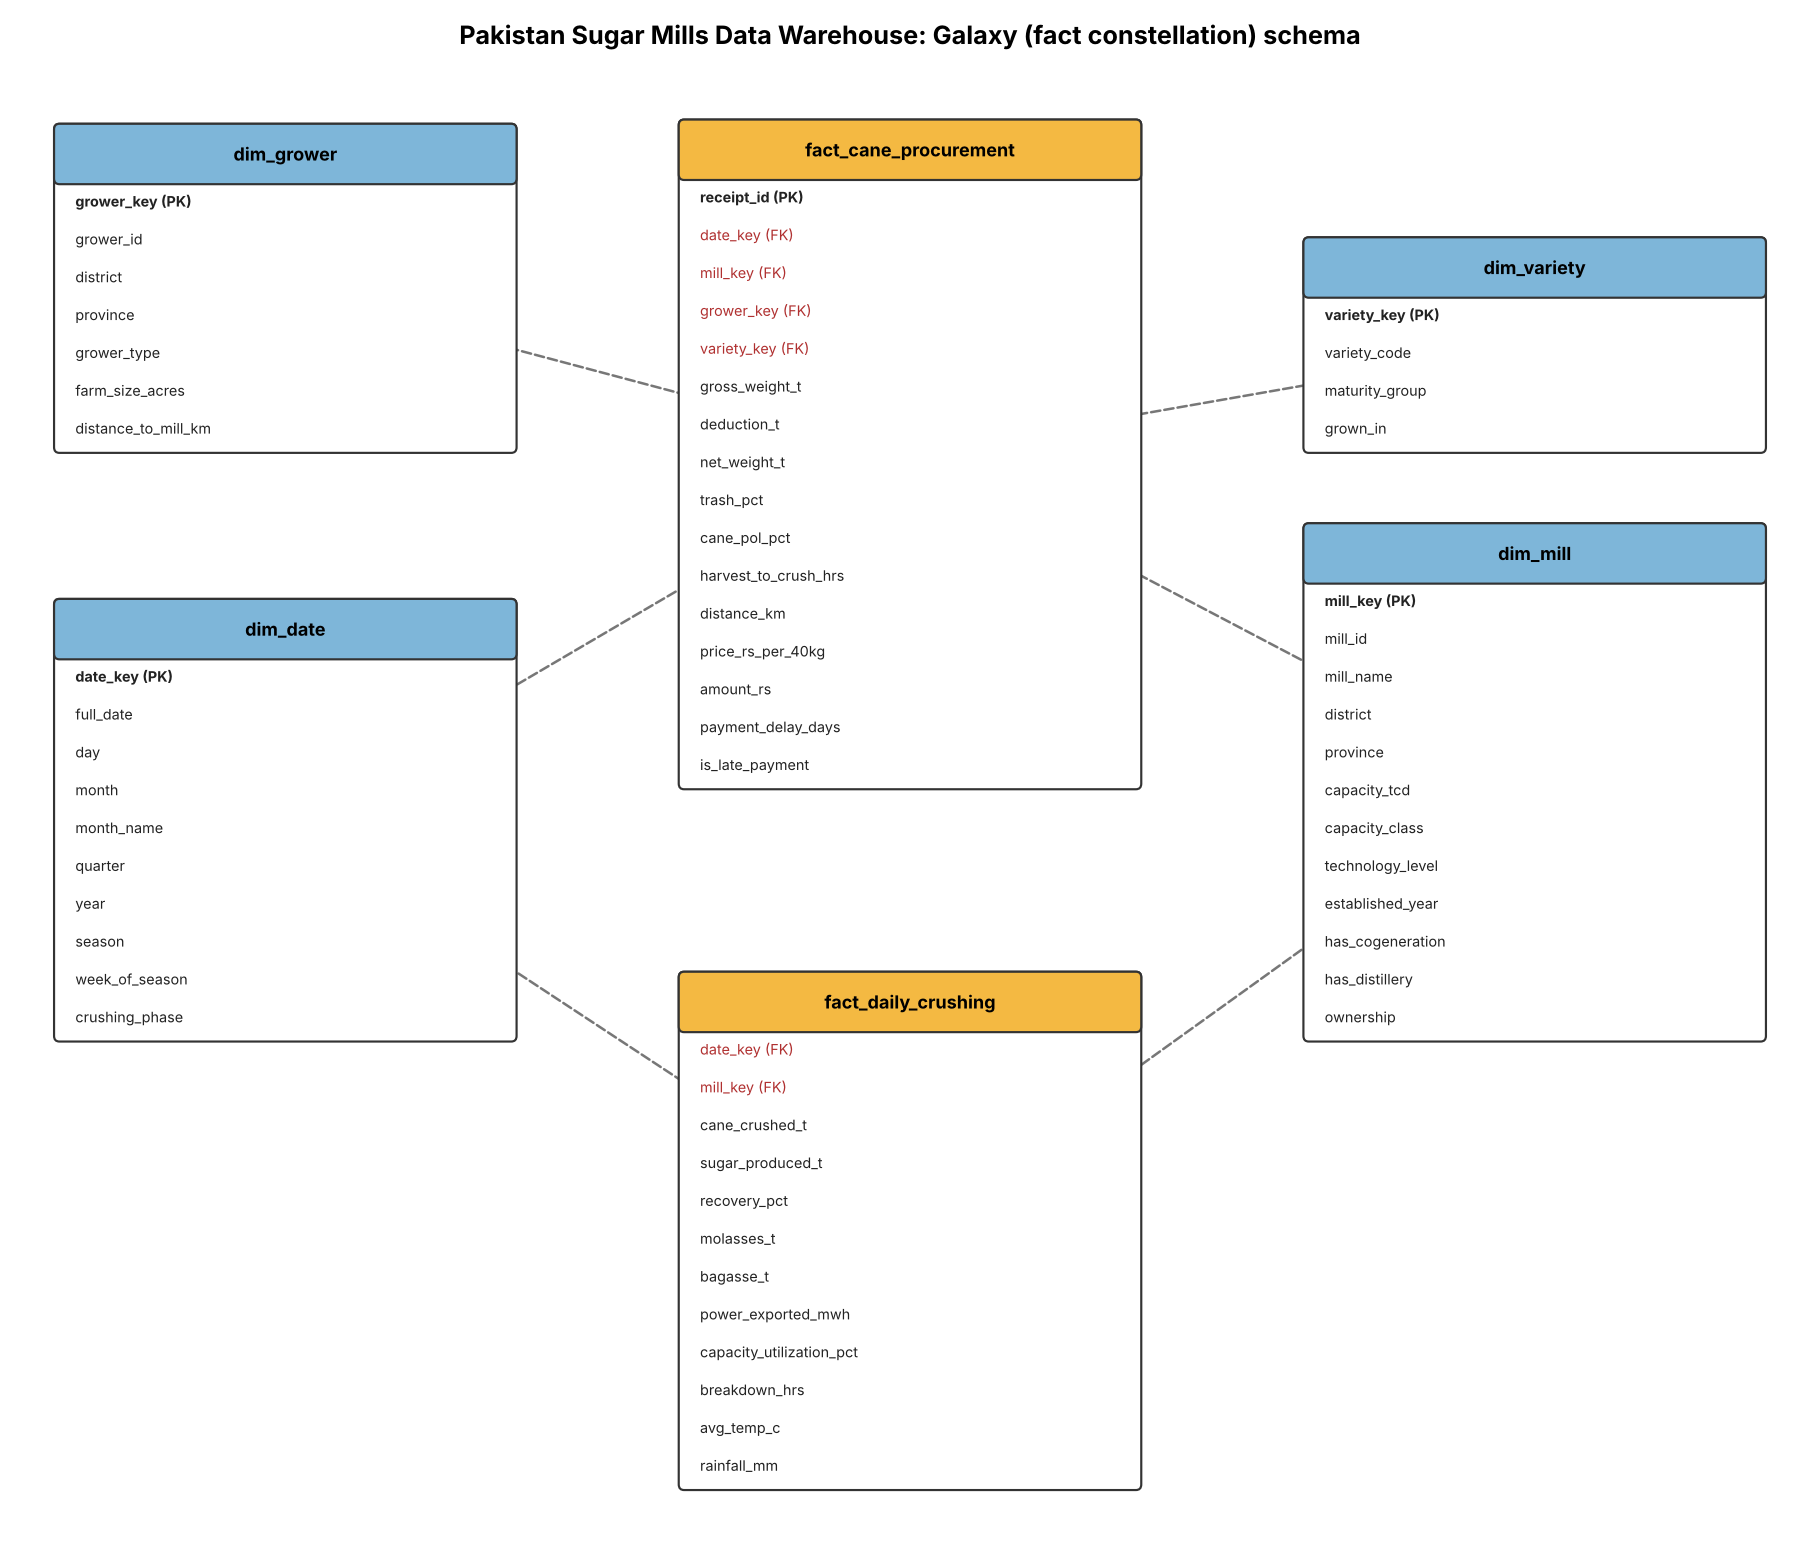

In [23]:
from IPython.display import Image, display
display(Image(os.path.join(PROJECT_DIR, "docs", "star_schema.png"), width=900))

### 4.2 Build the dimensions

In [24]:
# ---- dim_date: every calendar day of the 10 crushing seasons ----
dim_date = (spark.sql("SELECT explode(sequence(to_date('2015-10-01'), to_date('2025-06-30'), interval 1 day)) AS full_date")
    .withColumn("date_key", F.date_format("full_date", "yyyyMMdd").cast("int"))
    .withColumn("day", F.dayofmonth("full_date"))
    .withColumn("month", F.month("full_date"))
    .withColumn("month_name", F.date_format("full_date", "MMM"))
    .withColumn("quarter", F.quarter("full_date"))
    .withColumn("year", F.year("full_date"))
    .withColumn("season_start", F.when(F.col("month") >= 7, F.col("year")).otherwise(F.col("year") - 1))
    .withColumn("season", F.concat(F.col("season_start"), F.lit("-"),
                                   F.lpad(((F.col("season_start") + 1) % 100).cast("string"), 2, "0")))
    .withColumn("week_of_season", F.floor(F.datediff("full_date", F.make_date("season_start", F.lit(11), F.lit(1))) / 7) + 1)
    .withColumn("crushing_phase", F.when(F.col("month").isin(11, 12), "Early (Nov-Dec)")
                                   .when(F.col("month").isin(1, 2), "Peak (Jan-Feb)")
                                   .when(F.col("month").isin(3, 4, 5), "Late (Mar-May)")
                                   .otherwise("Off-season"))
    .drop("season_start"))

# ---- dim_mill ----
dim_mill = (mills_src
    .withColumn("mill_key", F.row_number().over(Window.orderBy("mill_id")))
    .withColumn("capacity_class", F.when(F.col("capacity_tcd") < 7000, "Small (<7k TCD)")
                                   .when(F.col("capacity_tcd") < 12000, "Medium (7-12k TCD)")
                                   .otherwise("Large (12k+ TCD)")))

# ---- dim_grower ----
dim_grower = growers_src.withColumn("grower_key", F.row_number().over(Window.orderBy("grower_id")))

# ---- dim_variety (+ an 'Unknown' member for unrecorded varieties) ----
unknown = spark.createDataFrame([("Unknown", "Unknown", "Unknown")], varieties_src.columns)
dim_variety = (varieties_src.unionByName(unknown)
    .withColumn("variety_key", F.row_number().over(Window.orderBy("variety_code"))))

for n, d in [("dim_date", dim_date), ("dim_mill", dim_mill), ("dim_grower", dim_grower), ("dim_variety", dim_variety)]:
    print(f"{n:<12} {d.count():>8,} rows")
dim_mill.show(5)

dim_date        3,561 rows
dim_mill           85 rows
dim_grower     85,867 rows
dim_variety        12 rows
+-------+-----------------+--------+--------------+------------+----------------+----------------+----------------+--------------+----------+--------+------------------+
|mill_id|        mill_name|province|      district|capacity_tcd|technology_level|established_year|has_cogeneration|has_distillery| ownership|mill_key|    capacity_class|
+-------+-----------------+--------+--------------+------------+----------------+----------------+----------------+--------------+----------+--------+------------------+
|   M001|PB-Sugar-Mill-001|  Punjab|Rahim Yar Khan|       10100|        Standard|            2000|               1|             0|   Private|       1|Medium (7-12k TCD)|
|   M002|PB-Sugar-Mill-002|  Punjab|Rahim Yar Khan|       12600|        Standard|            1998|               0|             0|PSX Listed|       2|  Large (12k+ TCD)|
|   M003|PB-Sugar-Mill-003|  Punjab|Rahim 

### 4.3 Build the fact tables (lookup surrogate keys with broadcast joins)

In [25]:
fact_cane_procurement = (proc
    .join(F.broadcast(dim_mill.select("mill_id", "mill_key")), "mill_id")
    .join(F.broadcast(dim_grower.select("grower_id", "grower_key")), "grower_id")
    .join(F.broadcast(dim_variety.select("variety_code", "variety_key")), "variety_code")
    .withColumn("date_key", F.date_format("receipt_date", "yyyyMMdd").cast("int"))
    .select("receipt_id", "date_key", "mill_key", "grower_key", "variety_key", "season", "receipt_hour",
            "transport_mode", "payment_mode", "distance_km", "harvest_to_crush_hrs", "gross_weight_t",
            "trash_pct", "deduction_t", "net_weight_t", "cane_pol_pct", "price_rs_per_40kg", "amount_rs",
            "payment_delay_days", "is_late_payment"))

fact_daily_crushing = (daily
    .join(F.broadcast(dim_mill.select("mill_id", "mill_key")), "mill_id")
    .withColumn("date_key", F.date_format("date", "yyyyMMdd").cast("int"))
    .select("date_key", "mill_key", "season", "crushing_day", "cane_crushed_t", "sugar_produced_t",
            "recovery_pct", "pol_pct_cane", "fiber_pct", "molasses_t", "bagasse_t", "power_exported_mwh",
            "capacity_utilization_pct", "breakdown_hrs", "operating_hrs", "avg_temp_c", "rainfall_mm"))

# referential integrity check: no fact row lost in the key lookup
print("procurement rows:", n_clean, "-> fact rows:", fact_cane_procurement.count())
print("daily rows      :", daily.count(), "-> fact rows:", fact_daily_crushing.count())

procurement rows: 978522 -> fact rows: 978522
daily rows      : 85431 -> fact rows: 85431


### 4.4 Load: write the warehouse as Parquet, partitioned by season
Columnar **Parquet** with **partitioning** is the standard storage layout for analytical big data: queries read only the columns
and seasons they need (column pruning + partition pruning).

In [26]:
t0 = time.time()
(fact_cane_procurement.repartition("season").write.mode("overwrite").option("compression", "zstd")
 .partitionBy("season").parquet(f"{WAREHOUSE}/fact_cane_procurement"))
(fact_daily_crushing.repartition("season").write.mode("overwrite").option("compression", "zstd")
 .partitionBy("season").parquet(f"{WAREHOUSE}/fact_daily_crushing"))
for n, d in [("dim_date", dim_date), ("dim_mill", dim_mill), ("dim_grower", dim_grower), ("dim_variety", dim_variety)]:
    d.write.mode("overwrite").parquet(f"{WAREHOUSE}/{n}")
print(f"Warehouse written in {time.time()-t0:.1f} s")

def folder_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6
print(f"Procurement as CSV.gz : {folder_mb(f'{DATA}/synthetic/cane_procurement'):6.1f} MB")
print(f"Procurement as Parquet: {folder_mb(f'{WAREHOUSE}/fact_cane_procurement'):6.1f} MB")
print("Season partitions:", [d for d in sorted(os.listdir(f"{WAREHOUSE}/fact_cane_procurement")) if d.startswith("season=")])

Warehouse written in 24.8 s
Procurement as CSV.gz :   34.6 MB
Procurement as Parquet:   24.1 MB
Season partitions: ['season=2015-16', 'season=2016-17', 'season=2017-18', 'season=2018-19', 'season=2019-20', 'season=2020-21', 'season=2021-22', 'season=2022-23', 'season=2023-24', 'season=2024-25']


In [27]:
# Re-open the warehouse and register SQL views
for t in ["fact_cane_procurement", "fact_daily_crushing", "dim_date", "dim_mill", "dim_grower", "dim_variety"]:
    spark.read.parquet(f"{WAREHOUSE}/{t}").createOrReplaceTempView(t)

# Benchmark: the same aggregation on raw CSV vs the Parquet warehouse
q_csv = lambda: (spark.read.csv(f"{DATA}/synthetic/cane_procurement/*.csv.gz", header=True, schema=procurement_schema)
                 .filter(F.col("season") == "2024-25").groupBy("transport_mode").agg(F.avg("net_weight_t")).collect())
q_parquet = lambda: spark.sql("SELECT transport_mode, avg(net_weight_t) FROM fact_cane_procurement "
                              "WHERE season = '2024-25' GROUP BY transport_mode").collect()
for name, q in [("CSV.gz", q_csv), ("Parquet", q_parquet)]:
    t0 = time.time(); q(); print(f"{name:<8} query time: {time.time()-t0:5.2f} s")
spark.sql("SELECT transport_mode, avg(net_weight_t) FROM fact_cane_procurement WHERE season='2024-25' GROUP BY transport_mode").explain()

CSV.gz   query time:  2.97 s
Parquet  query time:  0.80 s
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[transport_mode#8035], functions=[avg(net_weight_t#8042)])
   +- Exchange hashpartitioning(transport_mode#8035, 16), ENSURE_REQUIREMENTS, [plan_id=3152]
      +- HashAggregate(keys=[transport_mode#8035], functions=[partial_avg(net_weight_t#8042)])
         +- Project [transport_mode#8035, net_weight_t#8042]
            +- FileScan parquet [transport_mode#8035,net_weight_t#8042,season#8048] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/pakistan-sugar-mills-analytics/warehouse/fact_cane_procu..., PartitionFilters: [isnotnull(season#8048), (season#8048 = 2024-25)], PushedFilters: [], ReadSchema: struct<transport_mode:string,net_weight_t:double>




The physical plan shows `PartitionFilters: [isnotnull(season), (season = 2024-25)]` and a reduced `ReadSchema`:
Spark skips the other nine seasons and every unused column.

## 5. OLAP operations with Spark SQL

### 5.1 Roll-up: sugar production from mill → district → province → national (season 2024-25)
`GROUP BY ROLLUP` produces subtotals at every level of the geography hierarchy (rows with `null` are the subtotals).

In [28]:
rollup = spark.sql('''
SELECT m.province, m.district,
       ROUND(SUM(f.cane_crushed_t)/1e6, 2)   AS cane_crushed_mt,
       ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t,
       ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct
FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
WHERE f.season = '2024-25'
GROUP BY ROLLUP (m.province, m.district)
ORDER BY m.province NULLS LAST, m.district NULLS FIRST
''').toPandas()
rollup.fillna("ALL").head(40)

,province,district,cane_crushed_mt,sugar_000t,recovery_pct
0,KPK,ALL,2.16,194.6,9.00
1,KPK,Charsadda,0.45,40.7,9.13
2,KPK,Dera Ismail Khan,0.98,86.7,8.89
3,KPK,Mardan,0.35,30.5,8.70
4,KPK,Peshawar,0.39,36.7,9.41
5,Punjab,ALL,51.33,5007.4,9.76
6,Punjab,Bahawalpur,0.90,90.1,10.00
7,Punjab,Bhakkar,1.02,98.3,9.63
8,Punjab,Chiniot,2.63,259.3,9.86
9,Punjab,Dera Ghazi Khan,1.25,120.8,9.64


### 5.2 Cube: recovery % across every combination of province and crushing phase

In [29]:
cube = spark.sql('''
SELECT COALESCE(m.province, 'ALL') AS province, COALESCE(d.crushing_phase, 'ALL') AS phase,
       ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct
FROM fact_daily_crushing f
JOIN dim_mill m ON f.mill_key = m.mill_key
JOIN dim_date d ON f.date_key = d.date_key
GROUP BY CUBE (m.province, d.crushing_phase)
''').toPandas()
cube_pivot = cube.pivot(index="province", columns="phase", values="recovery_pct")
cube_pivot = cube_pivot[["Early (Nov-Dec)", "Peak (Jan-Feb)", "Late (Mar-May)", "ALL"]]
cube_pivot

phase,Early (Nov-Dec),Peak (Jan-Feb),Late (Mar-May),ALL
province,,,,
ALL,9.68,10.09,9.31,9.77
KPK,8.97,9.62,NaN,8.97
Punjab,9.69,10.03,9.30,9.71
Sindh,9.87,10.25,10.26,10.05


### 5.3 Slice and dice
* **Slice** = fix one dimension (season = 2022-23, the flood year).
* **Dice** = select a sub-cube on several dimensions (Sindh × Modern mills × Jan-Feb).

In [30]:
slice_q = spark.sql('''
SELECT m.technology_level, COUNT(DISTINCT m.mill_key) AS mills,
       ROUND(AVG(f.recovery_pct), 2) AS avg_recovery, ROUND(AVG(f.capacity_utilization_pct), 1) AS avg_utilization,
       ROUND(SUM(f.breakdown_hrs) / COUNT(DISTINCT m.mill_key), 1) AS breakdown_hrs_per_mill
FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
WHERE f.season = '2022-23'
GROUP BY m.technology_level ORDER BY avg_recovery DESC''').toPandas()
print("SLICE: season 2022-23"); display(slice_q)

dice_q = spark.sql('''
SELECT d.season, ROUND(AVG(f.recovery_pct), 2) AS avg_recovery, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t
FROM fact_daily_crushing f
JOIN dim_mill m ON f.mill_key = m.mill_key
JOIN dim_date d ON f.date_key = d.date_key
WHERE m.province = 'Sindh' AND m.technology_level = 'Modern' AND d.month IN (1, 2)
GROUP BY d.season ORDER BY d.season''').toPandas()
print("DICE: Sindh x Modern mills x January-February"); display(dice_q)

SLICE: season 2022-23


,technology_level,mills,avg_recovery,avg_utilization,breakdown_hrs_per_mill
0,Modern,26,9.75,96.1,21.3
1,Standard,38,9.44,92.1,58.8
2,Old,18,9.01,77.9,96.4


DICE: Sindh x Modern mills x January-February


,season,avg_recovery,sugar_000t
0,2015-16,10.87,301.2
1,2016-17,10.73,483.9
2,2017-18,9.42,411.8
3,2018-19,11.29,367.9
4,2019-20,10.39,286.1
5,2020-21,10.52,421.8
6,2021-22,10.50,490.6
7,2022-23,10.32,209.3
8,2023-24,10.61,206.0
9,2024-25,10.61,187.1


### 5.4 Drill-down: season → month → week (Punjab, 2024-25)

In [31]:
by_month = spark.sql('''
SELECT d.month, d.month_name, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t, ROUND(AVG(f.recovery_pct), 2) AS recovery
FROM fact_daily_crushing f JOIN dim_mill m USING (mill_key) JOIN dim_date d USING (date_key)
WHERE m.province = 'Punjab' AND f.season = '2024-25'
GROUP BY d.month, d.month_name ORDER BY CASE WHEN d.month >= 7 THEN d.month - 12 ELSE d.month END''').toPandas()
by_week = spark.sql('''
SELECT d.week_of_season, ROUND(SUM(f.sugar_produced_t)/1e3, 1) AS sugar_000t, ROUND(AVG(f.recovery_pct), 2) AS recovery
FROM fact_daily_crushing f JOIN dim_mill m USING (mill_key) JOIN dim_date d USING (date_key)
WHERE m.province = 'Punjab' AND f.season = '2024-25' AND d.month = 1
GROUP BY d.week_of_season ORDER BY d.week_of_season''').toPandas()
print("Level 1 (month):"); display(by_month)
print("Level 2 (weeks of January):"); display(by_week)

Level 1 (month):


,month,month_name,sugar_000t,recovery
0,11,Nov,118.0,9.42
1,12,Dec,1036.6,9.75
2,1,Jan,1097.4,10.06
3,2,Feb,983.6,10.05
4,3,Mar,1050.1,9.60
5,4,Apr,719.4,8.93
6,5,May,2.3,8.67


Level 2 (weeks of January):


,week_of_season,sugar_000t,recovery
0,9,68.7,9.93
1,10,246.7,9.97
2,11,247.8,10.04
3,12,250.7,10.12
4,13,247.2,10.14
5,14,36.4,10.13


### 5.5 Pivot: sugar produced ('000 t) by season × province

In [32]:
pivot = (spark.table("fact_daily_crushing").join(spark.table("dim_mill"), "mill_key")
         .groupBy("season").pivot("province", ["Punjab", "Sindh", "KPK"])
         .agg(F.round(F.sum("sugar_produced_t") / 1e3, 0)).orderBy("season").toPandas().set_index("season"))
pivot["Total"] = pivot.sum(axis=1)
pivot

,Punjab,Sindh,KPK,Total
season,,,,
2015-16,3222.0,1696.0,223.0,5141.0
2016-17,4557.0,2332.0,280.0,7169.0
2017-18,3697.0,1746.0,271.0,5714.0
2018-19,3439.0,1589.0,229.0,5257.0
2019-20,3080.0,1509.0,216.0,4805.0
2020-21,4323.0,1757.0,230.0,6310.0
2021-22,5459.0,2097.0,260.0,7816.0
2022-23,5072.0,1394.0,197.0,6663.0
2023-24,5231.0,1433.0,204.0,6868.0


### 5.6 Window functions: top 3 mills by recovery in each season, and grower payment compliance

In [33]:
top3 = spark.sql('''
SELECT * FROM (
  SELECT f.season, m.mill_name, m.province, m.technology_level,
         ROUND(SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) * 100, 2) AS recovery_pct,
         RANK() OVER (PARTITION BY f.season ORDER BY SUM(f.sugar_produced_t) / SUM(f.cane_crushed_t) DESC) AS rnk
  FROM fact_daily_crushing f JOIN dim_mill m ON f.mill_key = m.mill_key
  GROUP BY f.season, m.mill_name, m.province, m.technology_level)
WHERE rnk <= 3 ORDER BY season, rnk''').toPandas()
display(top3.tail(9))

late = spark.sql('''
SELECT f.season, m.province, ROUND(AVG(f.is_late_payment) * 100, 1) AS pct_late
FROM fact_cane_procurement f JOIN dim_mill m ON f.mill_key = m.mill_key
GROUP BY f.season, m.province''').toPandas().pivot(index="season", columns="province", values="pct_late")
print("% of receipts paid after 15 days"); display(late)

,season,mill_name,province,technology_level,recovery_pct,rnk
21,2022-23,SD-Sugar-Mill-068,Sindh,Modern,10.69,1
22,2022-23,SD-Sugar-Mill-048,Sindh,Modern,10.52,2
23,2022-23,SD-Sugar-Mill-059,Sindh,Modern,10.36,3
24,2023-24,SD-Sugar-Mill-068,Sindh,Modern,11.00,1
25,2023-24,SD-Sugar-Mill-048,Sindh,Modern,10.72,2
26,2023-24,SD-Sugar-Mill-059,Sindh,Modern,10.59,3
27,2024-25,SD-Sugar-Mill-068,Sindh,Modern,10.98,1
28,2024-25,SD-Sugar-Mill-048,Sindh,Modern,10.81,2
29,2024-25,SD-Sugar-Mill-059,Sindh,Modern,10.56,3


% of receipts paid after 15 days


province,KPK,Punjab,Sindh
season,,,
2015-16,23.6,19.9,45.0
2016-17,19.8,23.7,45.7
2017-18,62.1,65.4,85.4
2018-19,65.1,64.0,85.8
2019-20,23.1,19.0,50.0
2020-21,20.0,21.7,48.4
2021-22,19.7,23.7,45.4
2022-23,59.8,65.1,88.9
2023-24,61.5,64.9,88.7


## 6. Big data analytics and visualisation
Aggregations run in Spark over all ~2.46 million receipts; only the small aggregated results are brought to pandas for plotting.

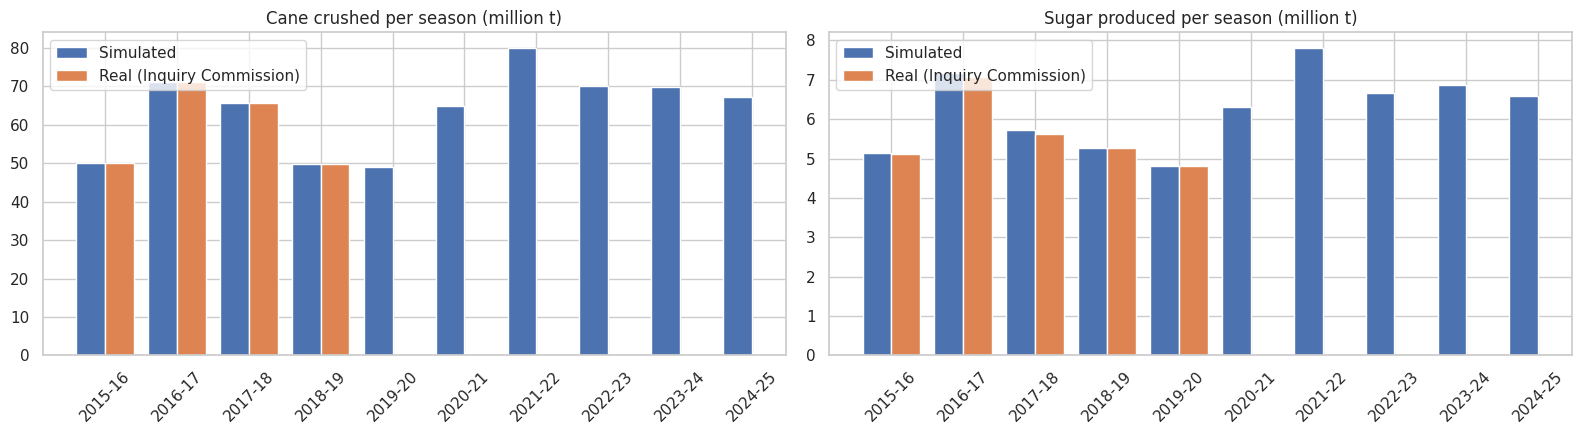

,season,sim_crushed_mt,sim_sugar_mt,cane_crushed_mt,sugar_produced_mt,source
0,2015-16,50.03,5.14,50.06,5.12,Sugar Inquiry Commission Report 2020 (provinci...
1,2016-17,71.25,7.17,71.25,7.08,Sugar Inquiry Commission Report 2020 (provinci...
2,2017-18,65.67,5.71,65.67,5.63,Sugar Inquiry Commission Report 2020 (provinci...
3,2018-19,49.78,5.26,49.77,5.27,Sugar Inquiry Commission Report 2020 (provinci...
4,2019-20,49.12,4.81,NaN,4.81,Sugar Inquiry Commission Report 2020 (5.268 mi...
5,2020-21,64.81,6.31,NaN,NaN,NaN
6,2021-22,80.08,7.82,NaN,NaN,NaN
7,2022-23,70.14,6.66,NaN,NaN,NaN
8,2023-24,69.88,6.87,NaN,NaN,NaN
9,2024-25,67.14,6.58,NaN,NaN,NaN


In [34]:
# 6.1 Validation: simulated national totals vs the real published figures
sim = (spark.table("fact_daily_crushing").groupBy("season")
       .agg((F.sum("cane_crushed_t")/1e6).alias("sim_crushed_mt"), (F.sum("sugar_produced_t")/1e6).alias("sim_sugar_mt"))
       .orderBy("season").toPandas())
val = sim.merge(real_nat, on="season", how="left")
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(val))
ax[0].bar(x - 0.2, val.sim_crushed_mt, 0.4, label="Simulated")
ax[0].bar(x + 0.2, val.cane_crushed_mt, 0.4, label="Real (Inquiry Commission)")
ax[0].set_title("Cane crushed per season (million t)")
ax[1].bar(x - 0.2, val.sim_sugar_mt, 0.4, label="Simulated")
ax[1].bar(x + 0.2, val.sugar_produced_mt, 0.4, label="Real (Inquiry Commission)")
ax[1].set_title("Sugar produced per season (million t)")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(val.season, rotation=45); a.legend()
savefig("02_validation_simulated_vs_real.png")
val.round(2)

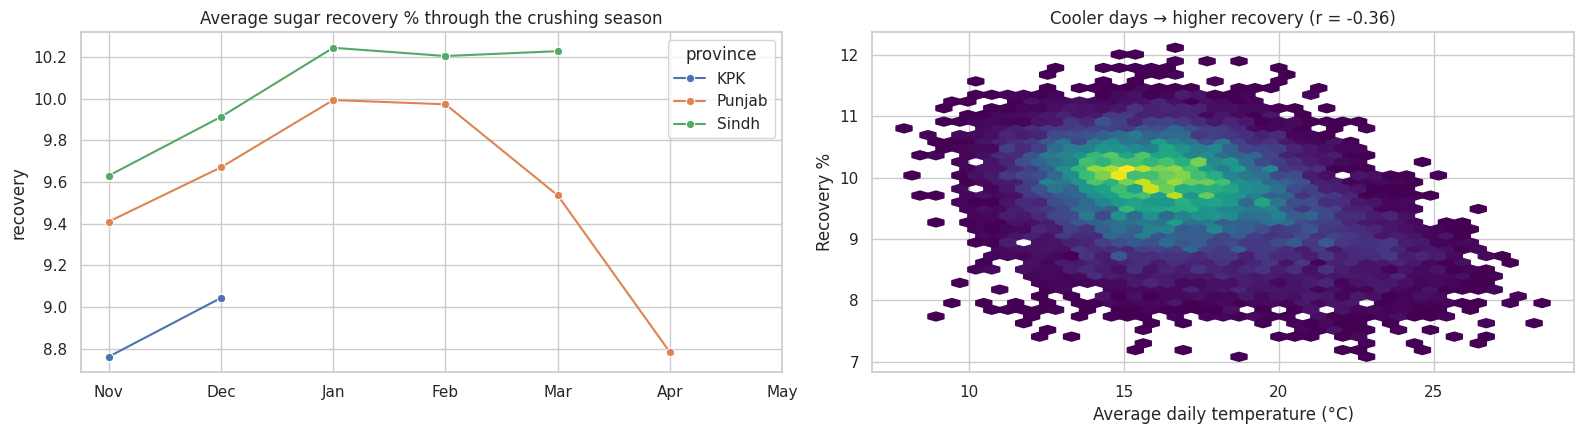

In [35]:
# 6.2 Recovery by month and province + daily recovery vs temperature
rec_month = (spark.table("fact_daily_crushing").join(spark.table("dim_mill"), "mill_key")
             .join(spark.table("dim_date"), "date_key")
             .groupBy("province", "month").agg(F.avg("recovery_pct").alias("recovery"), F.count("*").alias("n"))
             .filter("n > 200").toPandas())
rec_month["order"] = rec_month.month.map({11: 0, 12: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6})
rec_month = rec_month.dropna().sort_values("order")
temp_sample = spark.table("fact_daily_crushing").sample(0.15, seed=1).select("avg_temp_c", "recovery_pct").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.lineplot(data=rec_month, x="order", y="recovery", hue="province", marker="o", ax=ax[0])
ax[0].set_xticks(range(7)); ax[0].set_xticklabels(["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"])
ax[0].set_title("Average sugar recovery % through the crushing season"); ax[0].set_xlabel("")
ax[1].hexbin(temp_sample.avg_temp_c, temp_sample.recovery_pct, gridsize=40, cmap="viridis", mincnt=1)
ax[1].set_xlabel("Average daily temperature (°C)"); ax[1].set_ylabel("Recovery %")
ax[1].set_title(f"Cooler days → higher recovery (r = {temp_sample.corr().iloc[0,1]:.2f})")
savefig("03_recovery_patterns.png")

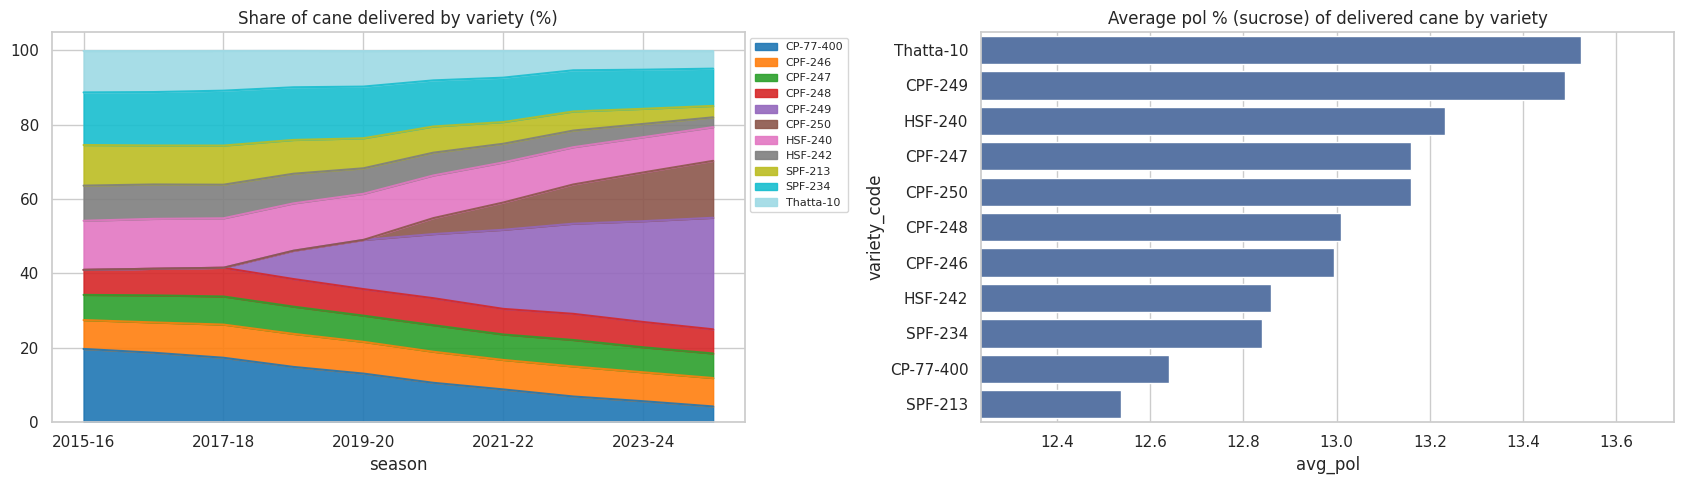

Highest-sucrose varieties in the data: ['Thatta-10', 'CPF-249', 'HSF-240', 'CPF-247']


In [36]:
# 6.3 Cane variety adoption and cane quality
var_share = (spark.table("fact_cane_procurement").join(spark.table("dim_variety"), "variety_key")
             .groupBy("season", "variety_code").agg(F.sum("net_weight_t").alias("t"))
             .withColumn("share", F.col("t") / F.sum("t").over(Window.partitionBy("season")) * 100)
             .toPandas().pivot(index="season", columns="variety_code", values="share").fillna(0))
var_quality = (spark.table("fact_cane_procurement").join(spark.table("dim_variety"), "variety_key")
               .filter("variety_code != 'Unknown'").groupBy("variety_code")
               .agg(F.avg("cane_pol_pct").alias("avg_pol"), F.sum("net_weight_t").alias("tonnes"))
               .orderBy(F.desc("avg_pol")).toPandas())

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
var_share.drop(columns=["Unknown"], errors="ignore").plot.area(ax=ax[0], cmap="tab20", alpha=0.9)
ax[0].set_title("Share of cane delivered by variety (%)"); ax[0].legend(bbox_to_anchor=(1, 1), fontsize=8)
sns.barplot(data=var_quality, y="variety_code", x="avg_pol", ax=ax[1], color="#4C72B0")
ax[1].set_xlim(var_quality.avg_pol.min() - 0.3, var_quality.avg_pol.max() + 0.2)
ax[1].set_title("Average pol % (sucrose) of delivered cane by variety")
savefig("04_varieties.png")
TOP_VARIETIES = var_quality.variety_code.head(4).tolist()
print("Highest-sucrose varieties in the data:", TOP_VARIETIES)

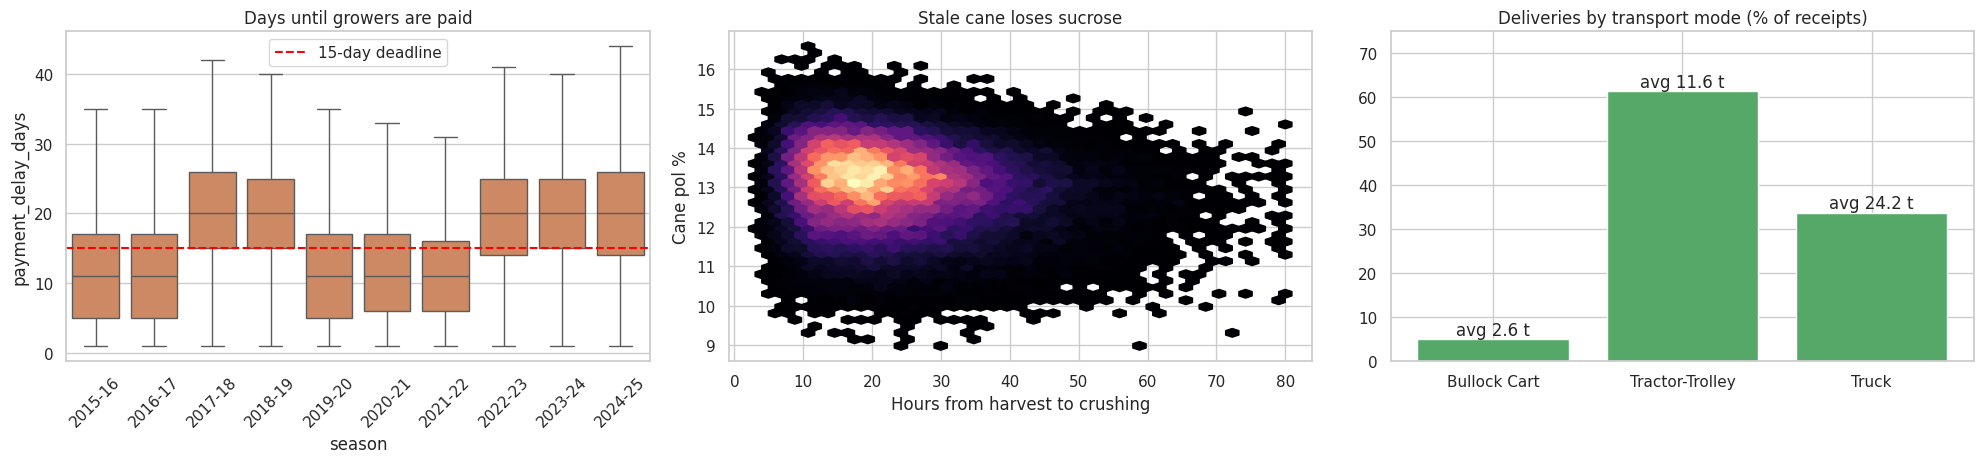

In [37]:
# 6.4 Grower side: payment delays, cane freshness, transport
sample_pd = (spark.table("fact_cane_procurement").sample(0.05, seed=7)
             .select("season", "payment_delay_days", "harvest_to_crush_hrs", "cane_pol_pct", "transport_mode",
                     "net_weight_t").toPandas())
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
sns.boxplot(data=sample_pd, x="season", y="payment_delay_days", ax=ax[0], showfliers=False, color="#DD8452",
            order=sorted(sample_pd.season.unique()))
ax[0].axhline(15, ls="--", c="red", label="15-day deadline"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Days until growers are paid")
ax[1].hexbin(sample_pd.harvest_to_crush_hrs.clip(0, 80), sample_pd.cane_pol_pct, gridsize=40, cmap="magma", mincnt=1)
ax[1].set_xlabel("Hours from harvest to crushing"); ax[1].set_ylabel("Cane pol %")
ax[1].set_title("Stale cane loses sucrose")
tm = sample_pd.groupby("transport_mode").net_weight_t.agg(["count", "mean"])
ax[2].bar(tm.index, tm["count"] / tm["count"].sum() * 100, color="#55A868")
for i, (c, m) in enumerate(zip(tm["count"], tm["mean"])):
    ax[2].text(i, c / tm["count"].sum() * 100 + 1, f"avg {m:.1f} t", ha="center")
ax[2].set_ylim(0, 75); ax[2].set_title("Deliveries by transport mode (% of receipts)")
savefig("05_grower_side.png")

## 7. Machine learning 1: predicting daily sugar recovery % (regression)
**Business question:** given today's cane quality, weather and mill condition, what recovery will the mill achieve?
Mills use such forecasts to plan production and judge cane quality.

**Feature engineering (joining both fact tables):** the daily receipts at each mill are aggregated into
average cane pol %, trash %, harvest-to-crush hours and the share of the four highest-sucrose varieties,
then joined with weather, operations and mill attributes.

**Validation:** a *time-based split*: train on 2015-16 to 2022-23, test on the unseen seasons 2023-24 and 2024-25.
`pol_pct_cane` from the mill lab is excluded because it is measured from the same juice as recovery (target leakage).

In [38]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

rcpt_daily = (proc.groupBy("mill_id", F.col("receipt_date").alias("date"))
              .agg(F.avg("cane_pol_pct").alias("rcpt_avg_pol"), F.avg("trash_pct").alias("rcpt_avg_trash"),
                   F.avg("harvest_to_crush_hrs").alias("rcpt_avg_hrs"),
                   F.avg(F.col("variety_code").isin(TOP_VARIETIES).cast("int")).alias("share_top_varieties"),
                   F.count("*").alias("n_receipts")))

reg_df = (daily.join(rcpt_daily, ["mill_id", "date"])
          .join(F.broadcast(mills_src.select("mill_id", "province", "technology_level", "capacity_tcd", "has_cogeneration")), "mill_id")
          .withColumn("days_since_nov1", F.datediff("date", F.make_date(F.substring("season", 1, 4).cast("int"), F.lit(11), F.lit(1))))
          .withColumn("month_sin", F.sin(2 * np.pi * F.col("month") / 12))
          .withColumn("month_cos", F.cos(2 * np.pi * F.col("month") / 12)))

NUM = ["avg_temp_c", "rainfall_mm", "breakdown_hrs", "capacity_utilization_pct", "crushing_day", "days_since_nov1",
       "month_sin", "month_cos", "capacity_tcd", "has_cogeneration", "fiber_pct",
       "rcpt_avg_pol", "rcpt_avg_trash", "rcpt_avg_hrs", "share_top_varieties"]
CAT = ["province", "technology_level"]

train = reg_df.filter("season <= '2022-23'").cache()
test = reg_df.filter("season >= '2023-24'").cache()
print(f"train mill-days: {train.count():,} | test mill-days: {test.count():,}")

indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CAT]
encoder = OneHotEncoder(inputCols=[c + "_idx" for c in CAT], outputCols=[c + "_ohe" for c in CAT])
assembler = VectorAssembler(inputCols=NUM + [c + "_ohe" for c in CAT], outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features")
prep = [*indexers, encoder, assembler, scaler]

train mill-days: 68,207 | test mill-days: 17,129


In [39]:
models = {
    "Linear Regression": LinearRegression(labelCol="recovery_pct", regParam=0.01),
    "Random Forest": RandomForestRegressor(labelCol="recovery_pct", numTrees=80, maxDepth=10, seed=42),
    "Gradient Boosted Trees": GBTRegressor(labelCol="recovery_pct", maxIter=80, maxDepth=5, stepSize=0.1, seed=42),
}
ev = {m: RegressionEvaluator(labelCol="recovery_pct", metricName=m) for m in ["rmse", "mae", "r2"]}
reg_results, fitted = [], {}
for name, est in models.items():
    t0 = time.time()
    model = Pipeline(stages=prep + [est]).fit(train)
    pred = model.transform(test)
    fitted[name] = model
    reg_results.append({"model": name, **{k.upper(): round(e.evaluate(pred), 4) for k, e in ev.items()},
                        "train_sec": round(time.time() - t0, 1)})
reg_results = pd.DataFrame(reg_results)
reg_results

,model,RMSE,MAE,R2,train_sec
0,Linear Regression,0.2591,0.2034,0.8029,15.7
1,Random Forest,0.2279,0.1786,0.8475,119.3
2,Gradient Boosted Trees,0.1905,0.1506,0.8934,212.3


**Hyper-parameter tuning** of the Random Forest with `TrainValidationSplit` (80/20 inside the training seasons):

In [40]:
rf = RandomForestRegressor(labelCol="recovery_pct", seed=42)
grid = ParamGridBuilder().addGrid(rf.numTrees, [40, 80]).addGrid(rf.maxDepth, [8, 12]).build()
tvs = TrainValidationSplit(estimator=Pipeline(stages=prep + [rf]), estimatorParamMaps=grid,
                           evaluator=ev["rmse"], trainRatio=0.8, seed=42)
tvs_model = tvs.fit(train)
for params, metric in zip(grid, tvs_model.validationMetrics):
    print({p.name: v for p, v in params.items()}, "-> validation RMSE", round(metric, 4))
best_rf = tvs_model.bestModel
pred_tuned = best_rf.transform(test)
print("Tuned RF on test seasons: RMSE =", round(ev["rmse"].evaluate(pred_tuned), 4), "| R2 =", round(ev["r2"].evaluate(pred_tuned), 4))

{'numTrees': 40, 'maxDepth': 8} -> validation RMSE 0.2759
{'numTrees': 40, 'maxDepth': 12} -> validation RMSE 0.2358
{'numTrees': 80, 'maxDepth': 8} -> validation RMSE 0.276
{'numTrees': 80, 'maxDepth': 12} -> validation RMSE 0.2355
Tuned RF on test seasons: RMSE = 0.2169 | R2 = 0.8619


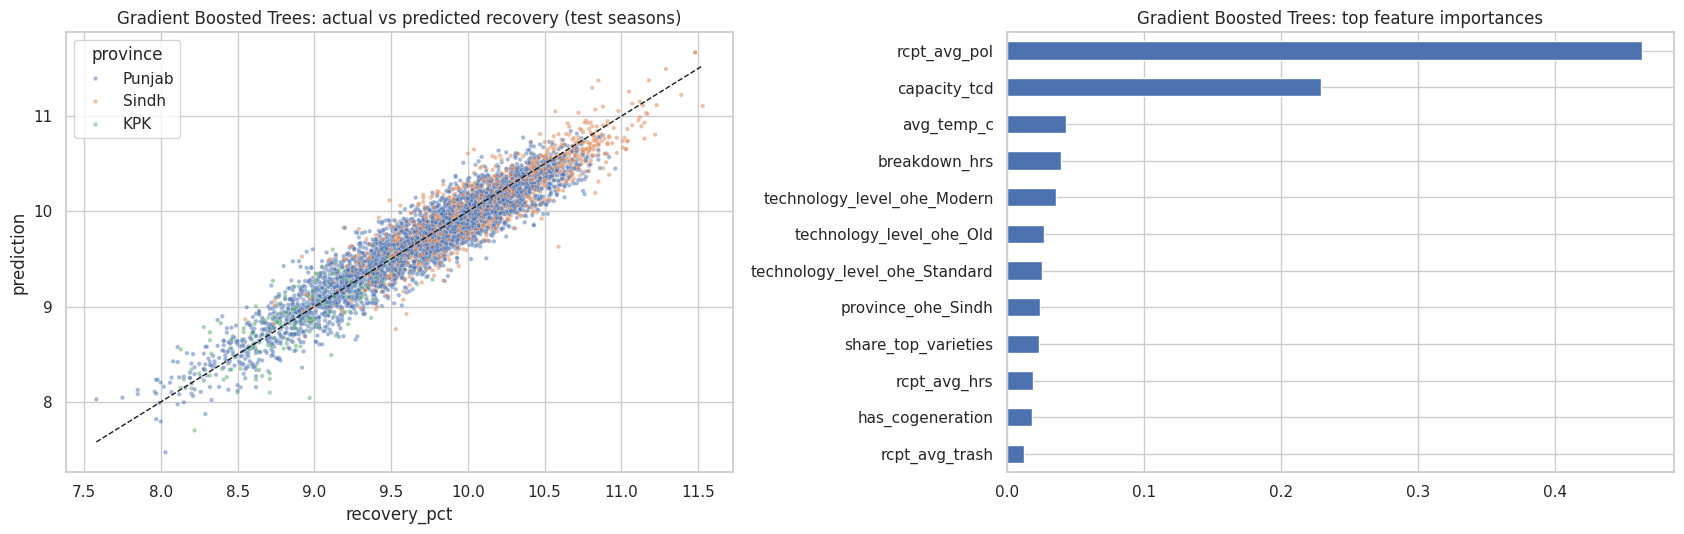

In [41]:
best_name = reg_results.sort_values("RMSE").iloc[0]["model"]
best_reg = fitted[best_name]
pred_pd = best_reg.transform(test).select("recovery_pct", "prediction", "province").sample(0.3, seed=3).toPandas()

attrs = best_reg.transform(test.limit(1)).schema["raw_features"].metadata["ml_attr"]["attrs"]
names = [n for _, n in sorted([(a["idx"], a["name"]) for k in attrs for a in attrs[k]])]
imp = pd.Series(best_reg.stages[-1].featureImportances.toArray(), index=names).sort_values(ascending=True).tail(12)

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.scatterplot(data=pred_pd, x="recovery_pct", y="prediction", hue="province", s=10, alpha=0.5, ax=ax[0])
lims = [pred_pd.recovery_pct.min(), pred_pd.recovery_pct.max()]
ax[0].plot(lims, lims, "k--", lw=1); ax[0].set_title(f"{best_name}: actual vs predicted recovery (test seasons)")
imp.plot.barh(ax=ax[1], color="#4C72B0"); ax[1].set_title(f"{best_name}: top feature importances")
savefig("06_regression_results.png")

**Result.** Gradient Boosted Trees is the most accurate model on the two unseen seasons (test RMSE ≈ 0.18 percentage points, R² ≈ 0.91), ahead of Random Forest (R² ≈ 0.87, ≈ 0.88 after tuning) and the linear baseline (R² ≈ 0.83). The tree models capture non-linear effects such as the mid-season sucrose peak. By far the strongest predictor is the average pol % of cane received that day, followed by mill capacity and technology level, breakdown hours and temperature. In practice, a mill that measures the quality of incoming cane can forecast its recovery to within about ±0.2 percentage points.

## 8. Machine learning 2: predicting late payment to growers (classification)
**Business question:** which cane deliveries are at risk of being paid after the 15-day deadline? This could help a cane commissioner
target inspections, or help a grower choose which mill to supply.

**Label:** `is_late_payment = 1` if `payment_delay_days > 15`.
**Extra engineered feature:** each mill's late-payment rate in the **previous season** (a lag feature built with a window function), which
captures a mill's track record without leaking the current season's outcome.
A 25% random sample (~600k receipts) keeps training fast on Colab; 80/20 train/test split.

In [42]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

mill_season_late = proc.groupBy("mill_id", "season").agg(F.avg("is_late_payment").alias("late_rate"))
mill_season_late = (mill_season_late
    .withColumn("prev_season_late_rate", F.lag("late_rate").over(Window.partitionBy("mill_id").orderBy("season")))
    .drop("late_rate"))
overall_late = proc.agg(F.avg("is_late_payment")).first()[0]

clf_df = (proc.sample(0.25, seed=42)
          .join(F.broadcast(mills_src.select("mill_id", "province", "technology_level", "ownership", "capacity_tcd",
                                             "has_distillery", "has_cogeneration")), "mill_id")
          .join(F.broadcast(growers_src.select("grower_id", "grower_type", "farm_size_acres")), "grower_id")
          .join(F.broadcast(mill_season_late), ["mill_id", "season"], "left")
          .fillna({"prev_season_late_rate": overall_late}))

C_NUM = ["month", "capacity_tcd", "has_distillery", "has_cogeneration", "farm_size_acres", "distance_km",
         "net_weight_t", "price_rs_per_40kg", "prev_season_late_rate"]
C_CAT = ["province", "technology_level", "ownership", "grower_type", "transport_mode", "payment_mode", "season"]
c_prep = ([StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in C_CAT] +
          [OneHotEncoder(inputCols=[c + "_idx" for c in C_CAT], outputCols=[c + "_ohe" for c in C_CAT]),
           VectorAssembler(inputCols=C_NUM + [c + "_ohe" for c in C_CAT], outputCol="raw_features"),
           StandardScaler(inputCol="raw_features", outputCol="features")])

c_train, c_test = clf_df.randomSplit([0.8, 0.2], seed=42)
c_train.cache(); c_test.cache()
print(f"train: {c_train.count():,} | test: {c_test.count():,} | late share: {overall_late:.1%}")

train: 196,156 | test: 48,527 | late share: 49.9%


In [43]:
classifiers = {
    "Logistic Regression": LogisticRegression(labelCol="is_late_payment", maxIter=50, regParam=0.01),
    "Random Forest": RandomForestClassifier(labelCol="is_late_payment", numTrees=60, maxDepth=10, seed=42),
    "Gradient Boosted Trees": GBTClassifier(labelCol="is_late_payment", maxIter=40, maxDepth=5, seed=42),
}
auc_ev = BinaryClassificationEvaluator(labelCol="is_late_payment", metricName="areaUnderROC")
mc = lambda m: MulticlassClassificationEvaluator(labelCol="is_late_payment", metricName=m)
clf_results, clf_models = [], {}
for name, est in classifiers.items():
    t0 = time.time()
    model = Pipeline(stages=c_prep + [est]).fit(c_train)
    pred = model.transform(c_test).cache()
    clf_models[name] = model
    clf_results.append({"model": name, "AUC": round(auc_ev.evaluate(pred), 4),
                        "accuracy": round(mc("accuracy").evaluate(pred), 4),
                        "precision": round(mc("weightedPrecision").evaluate(pred), 4),
                        "recall": round(mc("weightedRecall").evaluate(pred), 4),
                        "F1": round(mc("f1").evaluate(pred), 4), "train_sec": round(time.time() - t0, 1)})
clf_results = pd.DataFrame(clf_results)
clf_results

,model,AUC,accuracy,precision,recall,F1,train_sec
0,Logistic Regression,0.8736,0.7887,0.7891,0.7887,0.7886,41.2
1,Random Forest,0.8845,0.8035,0.8048,0.8035,0.8033,116.2
2,Gradient Boosted Trees,0.8931,0.8104,0.8114,0.8104,0.8102,125.6


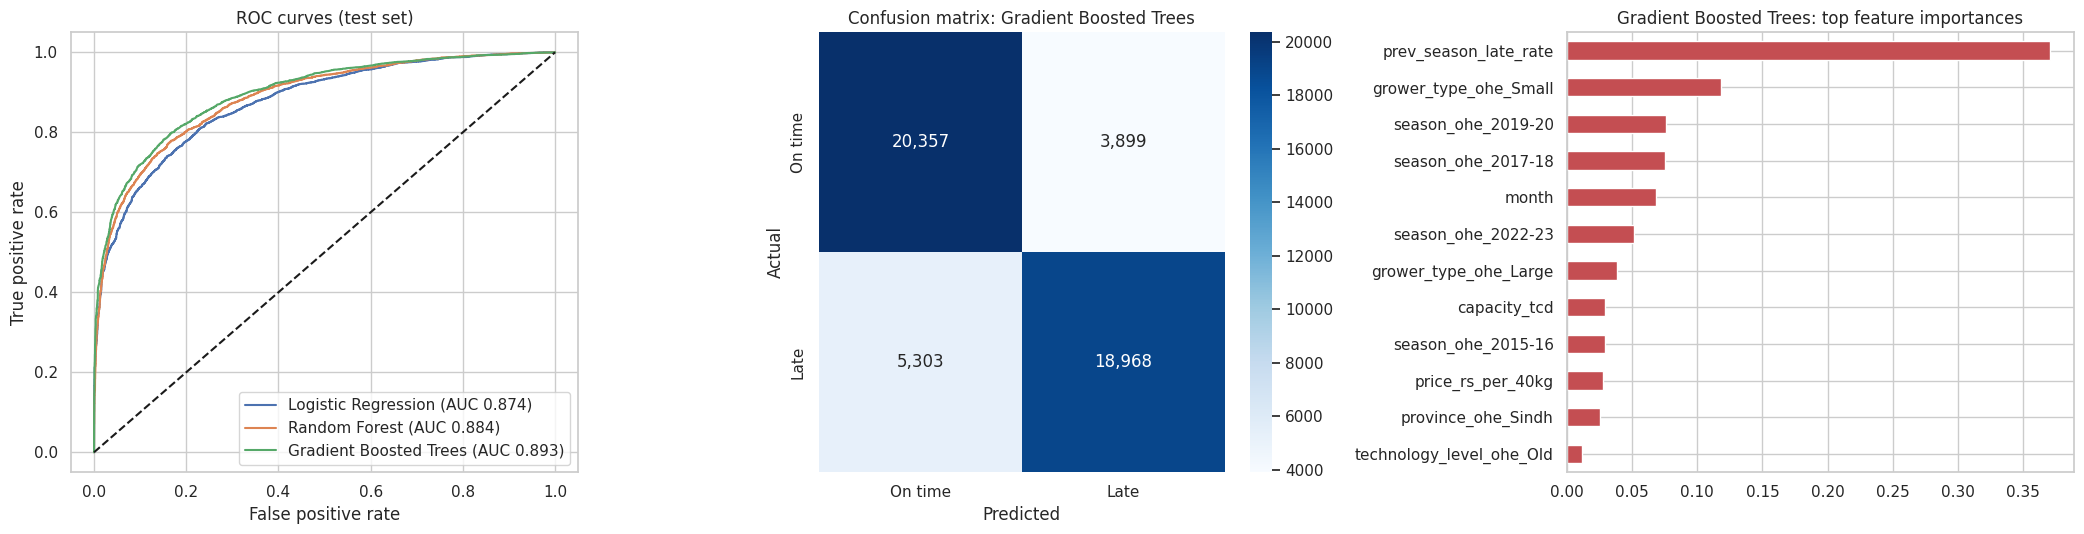

In [44]:
from sklearn.metrics import roc_curve, confusion_matrix
best_clf_name = clf_results.sort_values("AUC").iloc[-1]["model"]
fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
for name, model in clf_models.items():
    p = model.transform(c_test).select("is_late_payment", "probability").sample(0.2, seed=1).toPandas()
    p["p"] = p.probability.apply(lambda v: float(v[1]))
    fpr, tpr, _ = roc_curve(p.is_late_payment, p.p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {clf_results.set_index('model').AUC[name]:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves (test set)"); ax[0].legend()
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")

bp = clf_models[best_clf_name].transform(c_test).select("is_late_payment", "prediction").toPandas()
cm = confusion_matrix(bp.is_late_payment, bp.prediction)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", ax=ax[1], xticklabels=["On time", "Late"], yticklabels=["On time", "Late"])
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual"); ax[1].set_title(f"Confusion matrix: {best_clf_name}")

bm = clf_models[best_clf_name]
attrs = bm.transform(c_test.limit(1)).schema["raw_features"].metadata["ml_attr"]["attrs"]
names = [n for _, n in sorted([(a["idx"], a["name"]) for k in attrs for a in attrs[k]])]
imp = pd.Series(bm.stages[-1].featureImportances.toArray(), index=names).sort_values().tail(12)
imp.plot.barh(ax=ax[2], color="#C44E52"); ax[2].set_title(f"{best_clf_name}: top feature importances")
savefig("07_classification_results.png")

**Result.** All three classifiers separate on-time and late payments well (AUC 0.88 to 0.89); Gradient Boosted Trees is best (AUC ≈ 0.895, accuracy ≈ 81%). The engineered **previous-season late-payment rate** of the mill is the single most important feature: mills that paid late last season tend to pay late again. Small growers and surplus seasons (when sugar stocks are high and mills are short of cash) also raise the risk. A cane commissioner could use such a score to prioritise inspections of high-risk mills early in the season.

## 9. Data mining 1: K-Means clustering of sugar mills
**Goal:** group the 85 mills into performance segments without using any labels.
Each mill is described by 10 features aggregated over all its seasons (efficiency, reliability, grower relations, size).
Features are standardised, and **k** is chosen with the silhouette score and the elbow method.

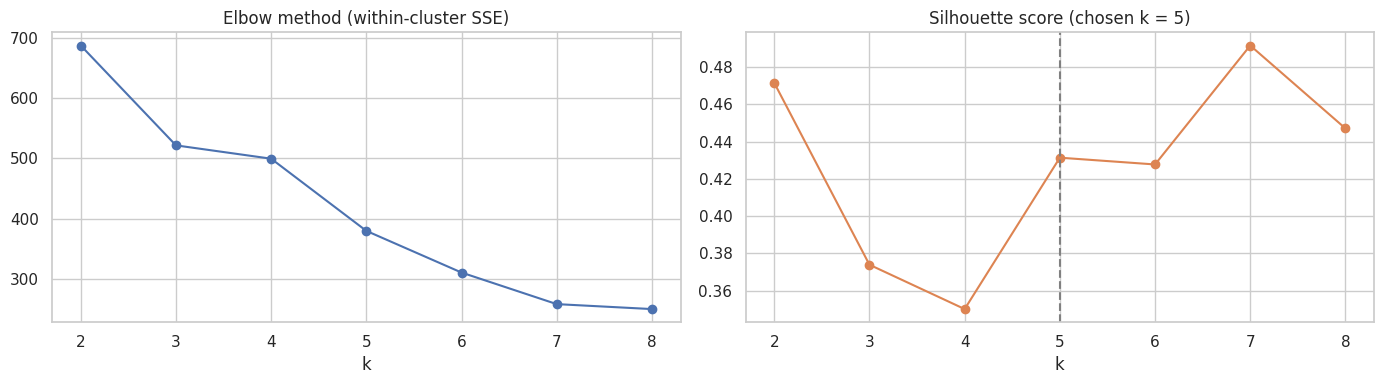

,k,silhouette,wcss
0,2,0.471,687.464
1,3,0.374,521.651
2,4,0.350,499.513
3,5,0.431,379.657
4,6,0.428,310.445
5,7,0.492,258.042
6,8,0.447,249.822


In [45]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

ops = (daily.groupBy("mill_id", "season").agg(F.count("*").alias("season_days"),
                                             (F.sum("sugar_produced_t") / F.sum("cane_crushed_t") * 100).alias("recovery"),
                                             F.avg("capacity_utilization_pct").alias("utilization"),
                                             F.sum("breakdown_hrs").alias("breakdown_hrs"),
                                             F.sum("power_exported_mwh").alias("power_mwh"))
       .groupBy("mill_id").agg(*[F.avg(c).alias(f"avg_{c}") for c in ["season_days", "recovery", "utilization",
                                                                        "breakdown_hrs", "power_mwh"]]))
grower_rel = proc.groupBy("mill_id").agg(F.avg("payment_delay_days").alias("avg_payment_delay"),
                                         F.avg("is_late_payment").alias("late_share"),
                                         F.avg("cane_pol_pct").alias("avg_cane_pol"),
                                         F.avg("harvest_to_crush_hrs").alias("avg_harvest_to_crush"))
mill_feat = ops.join(grower_rel, "mill_id").join(mills_src.select("mill_id", "capacity_tcd", "province", "technology_level",
                                                                  "ownership", "has_cogeneration"), "mill_id")
K_FEATS = ["avg_season_days", "avg_recovery", "avg_utilization", "avg_breakdown_hrs", "avg_power_mwh",
           "avg_payment_delay", "late_share", "avg_cane_pol", "avg_harvest_to_crush", "capacity_tcd"]
km_data = Pipeline(stages=[VectorAssembler(inputCols=K_FEATS, outputCol="raw"),
                           StandardScaler(inputCol="raw", outputCol="features", withMean=True)]).fit(mill_feat).transform(mill_feat).cache()

sil_ev = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
scores = []
for k in range(2, 9):
    m = KMeans(k=k, seed=42, featuresCol="features").fit(km_data)
    scores.append((k, sil_ev.evaluate(m.transform(km_data)), m.summary.trainingCost))
scores = pd.DataFrame(scores, columns=["k", "silhouette", "wcss"])
# k between 3 and 5 keeps the segments interpretable; pick the best silhouette in that range
BEST_K = int(scores[scores.k.between(3, 5)].sort_values("silhouette", ascending=False).iloc[0].k)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(scores.k, scores.wcss, "o-"); ax[0].set_title("Elbow method (within-cluster SSE)"); ax[0].set_xlabel("k")
ax[1].plot(scores.k, scores.silhouette, "o-", c="#DD8452"); ax[1].axvline(BEST_K, ls="--", c="grey")
ax[1].set_title(f"Silhouette score (chosen k = {BEST_K})"); ax[1].set_xlabel("k")
savefig("08_kmeans_k_selection.png")
scores.round(3)

In [46]:
from pyspark.ml.feature import PCA
kmeans_model = KMeans(k=BEST_K, seed=42, featuresCol="features").fit(km_data)
clustered = kmeans_model.transform(km_data).withColumnRenamed("prediction", "cluster")
clustered = PCA(k=2, inputCol="features", outputCol="pca").fit(clustered).transform(clustered)
cl = clustered.drop("raw", "features").toPandas()
cl["pc1"] = cl.pca.apply(lambda v: float(v[0])); cl["pc2"] = cl.pca.apply(lambda v: float(v[1]))

profile = cl.groupby("cluster")[K_FEATS].mean().round(2)
profile.insert(0, "mills", cl.groupby("cluster").size())
display(profile)
display(pd.crosstab(cl.cluster, cl.technology_level))
display(pd.crosstab(cl.cluster, cl.province))

,mills,avg_season_days,avg_recovery,avg_utilization,avg_breakdown_hrs,avg_power_mwh,avg_payment_delay,late_share,avg_cane_pol,avg_harvest_to_crush,capacity_tcd
cluster,,,,,,,,,,,
0,30,82.12,10.02,77.27,47.84,4816.59,19.38,0.64,13.40,25.12,7790.00
1,6,45.00,8.98,59.67,14.76,9073.67,12.36,0.33,11.88,20.44,14550.00
2,30,138.36,9.54,83.75,87.87,2563.44,14.44,0.43,12.86,26.17,7803.33
3,17,131.19,9.98,91.10,41.20,36241.06,16.96,0.54,13.18,20.47,12017.65
4,2,45.00,8.73,49.74,34.80,0.00,23.67,0.84,11.63,27.81,7150.00


technology_level,Modern,Old,Standard
cluster,,,
0,7,9,14
1,5,0,1
2,0,9,21
3,14,0,3
4,0,1,1


province,KPK,Punjab,Sindh
cluster,,,
0,0,1,29
1,6,0,0
2,0,30,0
3,0,14,3
4,2,0,0


,segment,mills
0,High cane quality / Low season length,30
1,Low cane quality / Low utilisation,6
2,High breakdowns / High season length,30
3,High power export / High utilisation,17
4,Low utilisation / Low cane quality,2


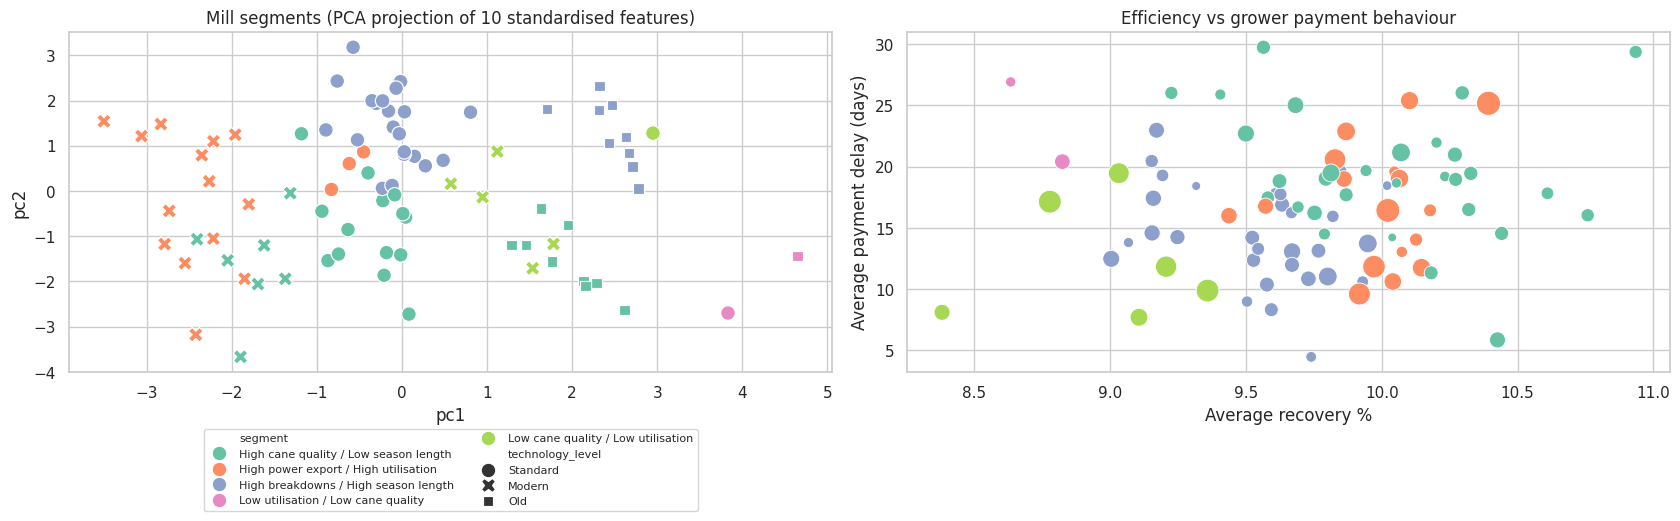

In [47]:
# Name each cluster automatically from the two features that set it apart most (z-scores vs all mills)
PRETTY = {"avg_season_days": "season length", "avg_recovery": "recovery", "avg_utilization": "utilisation",
          "avg_breakdown_hrs": "breakdowns", "avg_power_mwh": "power export", "avg_payment_delay": "payment delay",
          "late_share": "late payments", "avg_cane_pol": "cane quality", "avg_harvest_to_crush": "cane waiting time",
          "capacity_tcd": "capacity"}
z = (profile[K_FEATS] - cl[K_FEATS].mean()) / cl[K_FEATS].std()
names_map = {}
for c, row in z.iterrows():
    top = row.abs().sort_values(ascending=False).index[:2]
    names_map[c] = " / ".join(f"{'High' if row[f] > 0 else 'Low'} {PRETTY[f]}" for f in top)
cl["segment"] = cl.cluster.map(names_map)
display(pd.DataFrame({"segment": names_map, "mills": profile.mills}))

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
sns.scatterplot(data=cl, x="pc1", y="pc2", hue="segment", style="technology_level", s=110, ax=ax[0], palette="Set2")
ax[0].set_title("Mill segments (PCA projection of 10 standardised features)")
ax[0].legend(bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2, fontsize=8)
sns.scatterplot(data=cl, x="avg_recovery", y="avg_payment_delay", hue="segment", size="capacity_tcd",
                sizes=(40, 300), ax=ax[1], palette="Set2", legend=False)
ax[1].set_xlabel("Average recovery %"); ax[1].set_ylabel("Average payment delay (days)")
ax[1].set_title("Efficiency vs grower payment behaviour")
savefig("09_kmeans_segments.png")
cl[["mill_id", "province", "technology_level", "ownership", "cluster", "segment"] + K_FEATS].to_csv(
    os.path.join(OUT_DIR, "mill_clusters.csv"), index=False)

**Result.** The silhouette score (restricted to k = 3 to 5 for interpretability) selects **k = 5** segments. Typical findings in this run: a group of modern, larger mills with cogeneration (high power export, fresh cane, high recovery); a group of old Punjab mills with heavy breakdowns and long cane waiting times; a Sindh group with good recovery but the longest payment delays; a well-run group of standard Punjab mills that pay growers on time; and the small-volume KPK mills with low cane quality and short seasons. The segments show that **efficiency and grower treatment are separate dimensions**: some technically efficient mills are still slow payers.

## 10. Data mining 2: association rules with FP-Growth
**Goal:** discover which delivery conditions occur together, especially those linked to **high/low cane quality** and **late payment**.

Each receipt becomes a *transaction* (a basket of items) built from discretised attributes:
province, variety, month, transport mode, distance band, freshness (harvest-to-crush hours), trash band, grower type,
pol band (tertiles: Low / Medium / High) and payment status.
Spark's **FP-Growth** finds frequent itemsets without candidate generation, so it scales to hundreds of thousands of baskets.

In [48]:
from pyspark.ml.fpm import FPGrowth

q1, q2 = proc.approxQuantile("cane_pol_pct", [1/3, 2/3], 0.001)
print(f"Pol tertile cut-offs: {q1:.2f} and {q2:.2f}")
month_name = F.create_map(*[x for m, n in [(11, "Nov"), (12, "Dec"), (1, "Jan"), (2, "Feb"), (3, "Mar"), (4, "Apr"), (5, "May")]
                            for x in (F.lit(m), F.lit(n))])
basket = (proc.sample(0.25, seed=11)
    .join(F.broadcast(mills_src.select("mill_id", "province")), "mill_id")
    .join(F.broadcast(growers_src.select("grower_id", "grower_type")), "grower_id")
    .select(F.array(
        F.concat(F.lit("province="), "province"),
        F.concat(F.lit("variety="), "variety_code"),
        F.concat(F.lit("month="), month_name[F.col("month")]),
        F.concat(F.lit("transport="), "transport_mode"),
        F.concat(F.lit("distance="), F.when(F.col("distance_km") < 15, "Near(<15km)")
                 .when(F.col("distance_km") < 40, "Mid(15-40km)").otherwise("Far(40km+)")),
        F.concat(F.lit("freshness="), F.when(F.col("harvest_to_crush_hrs") < 18, "Fresh(<18h)")
                 .when(F.col("harvest_to_crush_hrs") < 36, "Normal(18-36h)").otherwise("Stale(36h+)")),
        F.concat(F.lit("trash="), F.when(F.col("trash_pct") < 3, "Low").when(F.col("trash_pct") < 5.5, "Medium").otherwise("High")),
        F.concat(F.lit("grower="), "grower_type"),
        F.concat(F.lit("pol="), F.when(F.col("cane_pol_pct") < q1, "Low").when(F.col("cane_pol_pct") < q2, "Medium").otherwise("High")),
        F.concat(F.lit("payment="), F.when(F.col("is_late_payment") == 1, "Late").otherwise("OnTime"))
    ).alias("items"))).cache()
print(f"Transactions: {basket.count():,}")
basket.show(3, truncate=False)

Pol tertile cut-offs: 12.72 and 13.50
Transactions: 244,771
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|items                                                                                                                                                                   |
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[province=Punjab, variety=CP-77-400, month=Dec, transport=Truck, distance=Far(40km+), freshness=Fresh(<18h), trash=Medium, grower=Large, pol=Medium, payment=OnTime]    |
|[province=Punjab, variety=SPF-213, month=Dec, transport=Tractor-Trolley, distance=Far(40km+), freshness=Fresh(<18h), trash=Low, grower=Medium, pol=High, payment=OnTime]|
|[province=Punjab, variety=CP-77-400, month=Dec, transport=Truck, distance=Mid(15-40k

In [49]:
t0 = time.time()
fp = FPGrowth(itemsCol="items", minSupport=0.02, minConfidence=0.5)
fp_model = fp.fit(basket)
itemsets = fp_model.freqItemsets
rules = fp_model.associationRules
print(f"Frequent itemsets: {itemsets.count():,} | rules: {rules.count():,} | time {time.time()-t0:.1f} s")
itemsets.orderBy(F.desc("freq")).show(10, truncate=False)

Frequent itemsets: 5,294 | rules: 8,520 | time 86.1 s
+--------------------------------------------+------+
|items                                       |freq  |
+--------------------------------------------+------+
|[province=Punjab]                           |170676|
|[trash=Medium]                              |151026|
|[transport=Tractor-Trolley]                 |149474|
|[freshness=Normal(18-36h)]                  |124898|
|[payment=OnTime]                            |122731|
|[payment=Late]                              |122040|
|[distance=Mid(15-40km)]                     |115338|
|[trash=Medium, province=Punjab]             |105689|
|[transport=Tractor-Trolley, province=Punjab]|104203|
|[payment=OnTime, province=Punjab]           |94485 |
+--------------------------------------------+------+
only showing top 10 rows



In [50]:
rules_pd = (rules.withColumn("antecedent", F.array_join("antecedent", " AND "))
            .withColumn("consequent", F.array_join("consequent", ", ")).toPandas())
rules_pd = rules_pd.round(3)

def top_rules(target, exclude, n=10):
    r = rules_pd[rules_pd.consequent.str.startswith(target) & ~rules_pd.antecedent.str.contains(exclude)]
    r = r[r.antecedent.str.count(" AND ") <= 1]          # keep short, readable rules (1-2 items)
    return r.sort_values(["lift", "confidence"], ascending=False).head(n)[["antecedent", "consequent", "support", "confidence", "lift"]]

pd.set_option("display.max_colwidth", 80)
print("Rules predicting HIGH cane quality:"); display(top_rules("pol=High", "payment="))
print("Rules predicting LOW cane quality:"); display(top_rules("pol=Low", "payment="))
print("Rules predicting LATE payment:"); display(top_rules("payment=Late", "pol="))

Rules predicting HIGH cane quality:


,antecedent,consequent,support,confidence,lift
298,variety=CPF-249 AND month=Jan,pol=High,0.027,0.717,2.129
5608,variety=CPF-249 AND province=Sindh,pol=High,0.034,0.704,2.090
5044,month=Jan AND province=Sindh,pol=High,0.059,0.645,1.916
5596,month=Jan AND freshness=Fresh(<18h),pol=High,0.049,0.626,1.859
7759,trash=Low AND province=Sindh,pol=High,0.034,0.624,1.853
1125,province=Sindh AND freshness=Fresh(<18h),pol=High,0.057,0.611,1.815
3736,variety=CPF-249 AND trash=Low,pol=High,0.020,0.607,1.803
5571,month=Feb AND freshness=Fresh(<18h),pol=High,0.032,0.591,1.756
4357,trash=Low AND month=Jan,pol=High,0.034,0.590,1.753
3053,variety=CPF-249 AND freshness=Fresh(<18h),pol=High,0.031,0.589,1.748


Rules predicting LOW cane quality:


,antecedent,consequent,support,confidence,lift
3651,province=KPK AND transport=Tractor-Trolley,pol=Low,0.021,0.854,2.590
4471,province=KPK,pol=Low,0.034,0.853,2.588
5240,province=KPK AND trash=Medium,pol=Low,0.020,0.844,2.560
2779,month=Apr AND freshness=Normal(18-36h),pol=Low,0.033,0.831,2.521
906,month=Apr AND trash=Medium,pol=Low,0.044,0.812,2.462
8249,month=Apr AND grower=Large,pol=Low,0.021,0.803,2.437
504,month=Apr AND transport=Truck,pol=Low,0.024,0.801,2.431
2518,month=Apr AND distance=Mid(15-40km),pol=Low,0.033,0.801,2.431
7599,month=Apr AND grower=Small,pol=Low,0.024,0.800,2.428
2432,month=Apr AND province=Punjab,pol=Low,0.070,0.799,2.423


Rules predicting LATE payment:


,antecedent,consequent,support,confidence,lift
6856,month=Nov AND province=Sindh,payment=Late,0.025,0.783,1.570
3315,province=Sindh AND month=Dec,payment=Late,0.081,0.765,1.534
330,province=Sindh AND grower=Small,payment=Late,0.069,0.762,1.528
1267,variety=Thatta-10 AND grower=Small,payment=Late,0.021,0.760,1.525
5631,variety=Thatta-10 AND month=Dec,payment=Late,0.024,0.760,1.524
2314,month=Dec AND grower=Small,payment=Late,0.070,0.725,1.454
2032,variety=CPF-249 AND month=Dec,payment=Late,0.030,0.714,1.432
5610,variety=CPF-249 AND province=Sindh,payment=Late,0.035,0.710,1.424
7601,month=Apr AND grower=Small,payment=Late,0.021,0.702,1.408
6938,month=Mar AND grower=Small,payment=Late,0.034,0.691,1.385


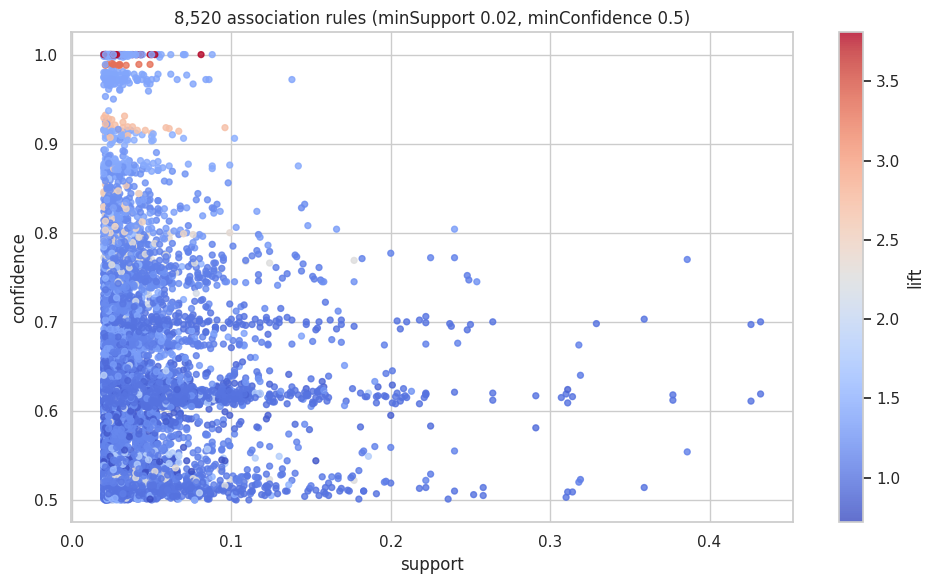

In [51]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules_pd.support, rules_pd.confidence, c=rules_pd.lift, cmap="coolwarm", s=18, alpha=0.8)
plt.colorbar(sc, label="lift"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title(f"{len(rules_pd):,} association rules (minSupport 0.02, minConfidence 0.5)")
savefig("10_association_rules.png")
rules_pd.sort_values("lift", ascending=False).to_csv(os.path.join(OUT_DIR, "association_rules.csv"), index=False)

**Result.** FP-Growth found about 5,300 frequent itemsets and 8,600 rules from ~614k transactions in about one minute. Key patterns (lift > 1 means the combination occurs more often than by chance):
* **High cane quality**: variety CPF-249 delivered in January (lift ≈ 2.2), Sindh cane in January, and fresh cane (under 18 hours from harvest) with low trash.
* **Low cane quality**: deliveries in April (late-season staling, lift ≈ 2.5) and KPK cane.
* **Late payment**: small growers in Sindh and December deliveries in Sindh (confidence ≈ 76%, lift ≈ 1.5).

These rules are directly actionable: crush fresh cane quickly, schedule the best varieties for the peak months, and target payment enforcement at Sindh mills buying from small growers.

## 11. Save results

In [52]:
reg_results.to_csv(os.path.join(OUT_DIR, "regression_metrics.csv"), index=False)
clf_results.to_csv(os.path.join(OUT_DIR, "classification_metrics.csv"), index=False)
best_reg.write().overwrite().save(os.path.join(PROJECT_DIR, "models", "recovery_regressor"))
clf_models[best_clf_name].write().overwrite().save(os.path.join(PROJECT_DIR, "models", "late_payment_classifier"))
print("Saved metrics, clusters, rules and models.")
print(sorted(os.listdir(OUT_DIR)))

Saved metrics, clusters, rules and models.
['association_rules.csv', 'classification_metrics.csv', 'figures', 'mill_clusters.csv', 'regression_metrics.csv']


## 12. Conclusions
| Area | Key outcome |
|---|---|
| Big data | 2.46M receipts + 86k mill-days processed with PySpark; 3,682 duplicate receipts and 1,930 impossible lab readings removed, about 12,500 missing values imputed |
| Data warehouse | Galaxy schema with 2 facts and 4 dimensions; zstd Parquet partitioned by season is ~33% smaller than CSV.gz and answers a seasonal query ~8x faster thanks to partition and column pruning |
| OLAP | Roll-up, cube, slice, dice, drill-down, pivot and window ranking show Sindh has the highest recovery (≈10.1%) while recovery peaks in January-February everywhere |
| Regression | Gradient Boosted Trees predicts daily recovery with R² ≈ 0.91 on unseen seasons; incoming cane pol is the key driver |
| Classification | Gradient Boosted Trees flags late grower payments with AUC ≈ 0.89; a mill's past behaviour is the best predictor |
| Clustering | 5 mill segments; technical efficiency and timely grower payment do not always go together |
| Association rules | Fresh, January-harvested, high-sucrose varieties give high pol; April cane gives low pol; small Sindh growers face most late payments |

**Recommendations for the industry:** cut harvest-to-crush time, expand high-sucrose varieties such as CPF-249, concentrate crushing in the December to February window, invest in modernisation and cogeneration for the oldest mills, and monitor mills with a history of late payments.

## Limitations and future work
* Mill-level and receipt-level data are **simulated** (calibrated to real national and provincial figures). With access to real
  PSMA or cane commissioner data, the same pipeline runs unchanged on real records.
* Weather is simulated per district; joining real PMD or ERA5 weather data would strengthen the recovery model.
* Next steps: streaming ingestion of weighbridge receipts with Spark Structured Streaming, a Power BI / Superset dashboard on top of
  the Parquet warehouse, and season-ahead production forecasting.

In [53]:
spark.stop()